# Năng lượng tái tạo tại ASEAN-10, 2000–2021

Notebook tự chứa này khảo sát và làm sạch 17 tệp CSV gốc trong `archive/` để xây dựng một mô hình dữ liệu phục vụ phân tích năng lượng tái tạo. Dữ liệu do **Our World in Data** tổng hợp từ **Ember** và **BP**; đối tượng chính là 10 quốc gia ASEAN: Brunei, Campuchia, Indonesia, Lào, Malaysia, Myanmar, Philippines, Singapore, Thái Lan và Việt Nam.

Cửa sổ phân tích chính là **2000–2021**. Năm 2022 vẫn được quan sát ở tầng dữ liệu gốc để chứng minh hiện tượng cắt cụt, nhưng không đi vào dữ liệu phân tích sạch. Notebook chỉ đọc các CSV gốc, xử lý trong bộ nhớ và không ghi tệp đầu ra.

In [1]:
# Bước 0.1 — Nạp thư viện và ghi nhận phiên bản để kết quả có thể tái lập.
import sys
import sqlite3
from itertools import combinations
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from IPython.display import display

if hasattr(sys.stdout, "reconfigure"):
    sys.stdout.reconfigure(encoding="utf-8", errors="replace")

library_versions = pd.Series(
    {
        "Python": sys.version.split()[0],
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "scipy": scipy.__version__,
        "matplotlib": matplotlib.__version__,
        "sqlite3": sqlite3.sqlite_version,
    },
    name="version",
).to_frame()
display(library_versions)

,version
Python,3.12.10
pandas,3.0.5
numpy,2.5.2
scipy,1.18.0
matplotlib,3.11.1
sqlite3,3.49.1


In [2]:
# Bước 0.2 — Đi ngược từ thư mục làm việc để tìm đúng thư mục chứa archive.
cwd = Path.cwd().resolve()
root_candidates = [cwd, *cwd.parents]
ROOT = next((path for path in root_candidates if (path / "archive").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError(
        "Không tìm thấy thư mục gốc có archive khi đi ngược từ Path.cwd()."
    )

ARCHIVE = ROOT / "archive"
ASEAN_COUNTRIES = [
    "Vietnam",
    "Thailand",
    "Indonesia",
    "Philippines",
    "Malaysia",
    "Singapore",
    "Myanmar",
    "Cambodia",
    "Laos",
    "Brunei",
]
ANALYSIS_YEARS = range(2000, 2022)
EXPECTED_CSV_COUNT = 17
KEY_COLUMNS = ["Entity", "Code", "Year"]
JOIN_COLUMNS = ["Entity", "Year"]

print(f"ROOT: {ROOT}")
print(f"Phạm vi: {len(ASEAN_COUNTRIES)} nước × {len(ANALYSIS_YEARS)} năm")

ROOT: D:\DA\Final_Project
Phạm vi: 10 nước × 22 năm


## 1.1. Câu hỏi phân tích

1. **Q1 — Quy mô và tốc độ:** Năng lượng tái tạo của ASEAN thay đổi thế nào trong tương quan với thế giới?
2. **Q2 — Cơ cấu:** Sự tăng trưởng đến từ công nghệ nào, và cơ cấu giữa thủy điện, gió, mặt trời, năng lượng tái tạo khác dịch chuyển ra sao?
3. **Q3 — Xếp hạng:** Thứ tự các nước ASEAN thay đổi thế nào khi đổi từ tổng năng lượng tái tạo sang gió + mặt trời?
4. **Q4 — Việt Nam:** Việt Nam đứng ở đâu trong khu vực và trên thế giới, và quỹ đạo riêng khác ASEAN-9 như thế nào?
5. **Q5 — Sản lượng hay tỷ trọng:** Sản lượng TWh và tỷ trọng trong điện năng có luôn kể cùng một câu chuyện không?
6. **Q6 — Mức tập trung:** Tăng trưởng của khu vực tập trung vào một vài nước hay đến từ số đông?

In [3]:
# Bước 1.1 — Đọc đúng 17 CSV trong archive và kiểm tra khóa cùng kiểu dữ liệu.
csv_paths = sorted(ARCHIVE.glob("*.csv"), key=lambda path: path.name)
if len(csv_paths) != EXPECTED_CSV_COUNT:
    raise ValueError(
        f"Cần đúng {EXPECTED_CSV_COUNT} CSV trong archive, tìm thấy {len(csv_paths)}."
    )

sources = {}
for csv_path in csv_paths:
    frame = pd.read_csv(
        csv_path,
        dtype={"Entity": "string", "Code": "string"},
        low_memory=False,
    )
    missing_keys = [column for column in KEY_COLUMNS if column not in frame.columns]
    if missing_keys:
        raise ValueError(f"{csv_path.name}: thiếu cột khóa {missing_keys}.")
    if frame.empty:
        raise ValueError(f"{csv_path.name}: tệp rỗng.")
    if frame["Entity"].isna().any() or frame["Entity"].str.strip().eq("").any():
        raise ValueError(f"{csv_path.name}: Entity có giá trị rỗng.")

    numeric_year = pd.to_numeric(frame["Year"], errors="coerce")
    invalid_year = numeric_year.isna() | ~np.isfinite(numeric_year)
    invalid_year |= numeric_year.notna() & numeric_year.mod(1).ne(0)
    if invalid_year.any():
        raise ValueError(f"{csv_path.name}: Year có giá trị không phải số nguyên.")
    frame["Year"] = numeric_year.astype("int64")
    if frame.duplicated(JOIN_COLUMNS).any():
        raise ValueError(f"{csv_path.name}: trùng khóa (Entity, Year).")

    metric_columns = [column for column in frame.columns if column not in KEY_COLUMNS]
    if not metric_columns:
        raise ValueError(f"{csv_path.name}: không có cột chỉ số.")
    for column in metric_columns:
        original = frame[column]
        numeric = pd.to_numeric(original, errors="coerce")
        invalid_value = original.notna() & (numeric.isna() | ~np.isfinite(numeric))
        if invalid_value.any():
            raise ValueError(f"{csv_path.name}/{column}: có giá trị không phải số hữu hạn.")
        frame[column] = numeric.astype("float64")
    sources[csv_path.name] = frame

print(f"Đã đọc {len(sources)} CSV; tổng số dòng: {sum(map(len, sources.values())):,}")
display(pd.DataFrame({"file_name": list(sources), "rows": [len(x) for x in sources.values()]}).head())

Đã đọc 17 CSV; tổng số dòng: 95,329


,file_name,rows
0,01 renewable-share-energy.csv,5603
1,02 modern-renewable-energy-consumption.csv,5610
2,03 modern-renewable-prod.csv,8851
3,04 share-electricity-renewables.csv,6871
4,05 hydropower-consumption.csv,8840


In [4]:
# Bước 1.2 — Lập hồ sơ từng cột chỉ số để tách giá trị 0 hợp lệ khỏi ô rỗng.
profile_records = []
for file_name, frame in sources.items():
    metric_columns = [column for column in frame.columns if column not in KEY_COLUMNS]
    for column in metric_columns:
        values = frame[column]
        valid = values.dropna()
        profile_records.append(
            {
                "file_name": file_name,
                "metric_column": column,
                "row_count": len(frame),
                "entity_count": int(frame["Entity"].nunique()),
                "year_min": int(frame["Year"].min()),
                "year_max": int(frame["Year"].max()),
                "missing_count": int(values.isna().sum()),
                "zero_count": int(valid.eq(0).sum()),
                "min_value": valid.min() if len(valid) else pd.NA,
                "max_value": valid.max() if len(valid) else pd.NA,
            }
        )

data_profile = pd.DataFrame(profile_records)
print(f"Hồ sơ: {data_profile.shape[0]} cột chỉ số thuộc {data_profile['file_name'].nunique()} tệp")
display(data_profile.head(10))

Hồ sơ: 23 cột chỉ số thuộc 17 tệp


,file_name,metric_column,row_count,entity_count,year_min,year_max,missing_count,zero_count,min_value,max_value
0,01 renewable-share-energy.csv,Renewables (% equivalent primary energy),5603,104,1965,2021,0,372,0.0,86.874535
1,02 modern-renewable-energy-consumption.csv,Geo Biomass Other - TWh,5610,104,1965,2021,144,1914,0.0,762.782650
2,02 modern-renewable-energy-consumption.csv,Solar Generation - TWh,5610,104,1965,2021,168,3318,0.0,1032.501200
3,02 modern-renewable-energy-consumption.csv,Wind Generation - TWh,5610,104,1965,2021,165,3056,0.0,1861.939800
4,02 modern-renewable-energy-consumption.csv,Hydro Generation - TWh,5610,104,1965,2021,7,562,0.0,4345.990000
5,03 modern-renewable-prod.csv,Electricity from wind (TWh),8851,251,1965,2022,175,5788,0.0,1848.260000
6,03 modern-renewable-prod.csv,Electricity from hydro (TWh),8851,251,1965,2022,11,1748,0.0,4340.610000
7,03 modern-renewable-prod.csv,Electricity from solar (TWh),8851,251,1965,2022,168,5984,0.0,1040.500000
8,03 modern-renewable-prod.csv,Other renewables including bioenergy (TWh),8851,251,1965,2022,220,3952,0.0,761.930050
9,04 share-electricity-renewables.csv,Renewables (% electricity),6871,246,1985,2022,0,1037,0.0,100.000015


In [5]:
# Bước 1.3 — Nhóm tệp theo số thực thể và biên năm để nhận diện các tầng độ phủ.
coverage_records = []
for file_name, frame in sources.items():
    coverage_records.append(
        {
            "file_name": file_name,
            "entity_count": int(frame["Entity"].nunique()),
            "year_min": int(frame["Year"].min()),
            "year_max": int(frame["Year"].max()),
            "key_count": int(frame[JOIN_COLUMNS].drop_duplicates().shape[0]),
        }
    )

file_coverage = pd.DataFrame(coverage_records)
coverage_tiers = (
    file_coverage.groupby(["entity_count", "year_min", "year_max"], as_index=False)
    .agg(
        file_count=("file_name", "size"),
        file_codes=("file_name", lambda values: ", ".join(name[:2] for name in values)),
        key_count_min=("key_count", "min"),
        key_count_max=("key_count", "max"),
    )
    .sort_values(["entity_count", "year_min", "year_max"], ascending=[False, True, False])
    .reset_index(drop=True)
)
coverage_tiers.insert(0, "tier_id", [f"T{i}" for i in range(1, len(coverage_tiers) + 1)])
display(coverage_tiers)

,tier_id,entity_count,year_min,year_max,file_count,file_codes,key_count_min,key_count_max
0,T1,251,1965,2022,4,"03, 05, 08, 12",8676,8851
1,T2,246,1985,2022,4,"04, 07, 11, 15",6871,6925
2,T3,104,1965,2021,5,"01, 02, 06, 10, 14",5442,5610
3,T4,64,1996,2021,1,13,1659,1659
4,T5,62,1995,2021,1,09,1540,1540
5,T6,35,1990,2021,1,16,1081,1081
6,T7,33,1975,2020,1,17,758,758


In [6]:
# Bước 1.4 — Tạo ma trận ASEAN-10 × 17 tệp; Y nghĩa là có ít nhất một khóa Entity-Year.
asean_coverage_matrix = pd.DataFrame(index=ASEAN_COUNTRIES)
for file_name, frame in sources.items():
    present = set(frame["Entity"].dropna())
    asean_coverage_matrix[file_name[:2]] = [
        "Y" if country in present else "–" for country in ASEAN_COUNTRIES
    ]
asean_coverage_matrix.index.name = "country"

print(f"Kích thước ma trận: {asean_coverage_matrix.shape}")
display(asean_coverage_matrix)

Kích thước ma trận: (10, 17)


,01,02,03,04,05,06,07,08,09,10,11,12,13,14,15,16,17
country,,,,,,,,,,,,,,,,,
Vietnam,Y,Y,Y,Y,Y,Y,Y,Y,–,Y,Y,Y,Y,Y,Y,–,–
Thailand,Y,Y,Y,Y,Y,Y,Y,Y,Y,Y,Y,Y,Y,Y,Y,Y,–
Indonesia,Y,Y,Y,Y,Y,Y,Y,Y,–,Y,Y,Y,–,Y,Y,Y,Y
Philippines,Y,Y,Y,Y,Y,Y,Y,Y,Y,Y,Y,Y,Y,Y,Y,–,Y
Malaysia,Y,Y,Y,Y,Y,Y,Y,Y,–,Y,Y,Y,Y,Y,Y,–,–
Singapore,Y,Y,Y,Y,Y,Y,Y,Y,–,Y,Y,Y,–,Y,Y,–,–
Myanmar,–,–,Y,Y,Y,–,Y,Y,–,–,Y,Y,–,–,Y,–,–
Cambodia,–,–,Y,Y,Y,–,Y,Y,–,–,Y,Y,–,–,Y,–,–
Laos,–,–,Y,Y,Y,–,Y,Y,–,–,Y,Y,–,–,Y,–,–


In [7]:
# Bước 1.5 — So sánh các nguồn TWh cùng đại lượng bằng đồng thời ngưỡng tuyệt đối và tương đối.
MATERIAL_ABS_TWH = 0.05
MATERIAL_REL_PCT = 1.0
OVERLAP_RTOL = 1e-9
OVERLAP_ATOL = 1e-12
METRIC_GROUPS = {
    "hydro_twh": [
        ("02 modern-renewable-energy-consumption.csv", "Hydro Generation - TWh"),
        ("03 modern-renewable-prod.csv", "Electricity from hydro (TWh)"),
        ("05 hydropower-consumption.csv", "Electricity from hydro (TWh)"),
    ],
    "wind_twh": [
        ("02 modern-renewable-energy-consumption.csv", "Wind Generation - TWh"),
        ("03 modern-renewable-prod.csv", "Electricity from wind (TWh)"),
        ("08 wind-generation.csv", "Electricity from wind (TWh)"),
    ],
    "solar_twh": [
        ("02 modern-renewable-energy-consumption.csv", "Solar Generation - TWh"),
        ("03 modern-renewable-prod.csv", "Electricity from solar (TWh)"),
        ("12 solar-energy-consumption.csv", "Electricity from solar (TWh)"),
    ],
    "other_renewables_twh": [
        ("02 modern-renewable-energy-consumption.csv", "Geo Biomass Other - TWh"),
        ("03 modern-renewable-prod.csv", "Other renewables including bioenergy (TWh)"),
    ],
}

overlap_summaries = []
overlap_details = []
for metric_group, metric_sources in METRIC_GROUPS.items():
    for (left_file, left_column), (right_file, right_column) in combinations(metric_sources, 2):
        left = sources[left_file][JOIN_COLUMNS + [left_column]].rename(
            columns={left_column: "left_value"}
        )
        right = sources[right_file][JOIN_COLUMNS + [right_column]].rename(
            columns={right_column: "right_value"}
        )
        merged = left.merge(right, on=JOIN_COLUMNS, how="inner", validate="one_to_one")
        comparable = merged.dropna(subset=["left_value", "right_value"]).copy()
        comparable["abs_diff"] = (comparable["left_value"] - comparable["right_value"]).abs()
        scale = comparable[["left_value", "right_value"]].abs().max(axis=1)
        comparable["rel_diff_pct"] = np.where(
            scale.gt(0), comparable["abs_diff"] / scale * 100.0, 0.0
        )
        is_difference = ~np.isclose(
            comparable["left_value"],
            comparable["right_value"],
            rtol=OVERLAP_RTOL,
            atol=OVERLAP_ATOL,
        )
        is_material = (
            is_difference
            & comparable["abs_diff"].gt(MATERIAL_ABS_TWH)
            & comparable["rel_diff_pct"].gt(MATERIAL_REL_PCT)
        )
        comparable["difference_label"] = np.where(is_material, "MATERIAL", "IMMATERIAL")


        detail = comparable.loc[is_difference].copy()
        detail.insert(0, "metric_group", metric_group)
        detail.insert(1, "left_file", left_file)
        detail.insert(2, "right_file", right_file)
        overlap_details.append(detail)

        left_keys = set(left.dropna(subset=["left_value"])[JOIN_COLUMNS].itertuples(index=False, name=None))
        right_keys = set(right.dropna(subset=["right_value"])[JOIN_COLUMNS].itertuples(index=False, name=None))
        material_count = int(is_material.sum())
        immaterial_count = int((is_difference & ~is_material).sum())
        if material_count:
            classification = "conflicting_overlap"
        elif left_keys < right_keys or right_keys < left_keys:
            classification = "redundant_subset"
        elif immaterial_count:
            classification = "immaterial_variant"
        else:
            classification = "exact_duplicate"
        overlap_summaries.append(
            {
                "metric_group": metric_group,
                "left_file": left_file[:2],
                "right_file": right_file[:2],
                "comparable_count": len(comparable),
                "exact_or_close_count": int((~is_difference).sum()),
                "immaterial_diff_count": immaterial_count,
                "material_diff_count": material_count,
                "max_abs_diff": comparable["abs_diff"].max(),
                "classification": classification,
            }
        )

overlap_summary = pd.DataFrame(overlap_summaries)
overlap_detail = pd.concat(overlap_details, ignore_index=True)
assert set(overlap_detail["difference_label"].unique()) <= {"MATERIAL", "IMMATERIAL"}
print(f"Đã so sánh {len(overlap_summary)} cặp; chi tiết chỉ giữ {len(overlap_detail):,} dòng có sai khác.")
display(overlap_summary)

Đã so sánh 10 cặp; chi tiết chỉ giữ 12,168 dòng có sai khác.


,metric_group,left_file,right_file,comparable_count,exact_or_close_count,immaterial_diff_count,material_diff_count,max_abs_diff,classification
0,hydro_twh,02,03,5603,3593,1469,541,159.168940,conflicting_overlap
1,hydro_twh,02,05,5603,3593,1469,541,159.168940,conflicting_overlap
2,hydro_twh,03,05,8840,8840,0,0,0.000000,exact_duplicate
3,wind_twh,02,03,5445,3769,1458,218,13.679800,conflicting_overlap
4,wind_twh,02,08,5445,3769,1458,218,13.679800,conflicting_overlap
5,wind_twh,03,08,8676,8676,0,0,0.000000,exact_duplicate
6,solar_twh,02,03,5442,3878,1248,316,7.998800,conflicting_overlap
7,solar_twh,02,12,5442,3878,1248,316,7.998800,conflicting_overlap
8,solar_twh,03,12,8683,8683,0,0,0.000000,exact_duplicate
9,other_renewables_twh,02,03,5466,3798,960,708,26.840298,conflicting_overlap


In [8]:
# Bước 1.6 — Kiểm tra lỗ hổng nội chuỗi, lịch lấy mẫu và mức cắt cụt của năm cuối.
BASELINE_YEARS = 5
SEVERE_COVERAGE_PCT = 50.0
FULL_COVERAGE_PCT = 95.0
PRIMARY_SOURCE_FILE = "03 modern-renewable-prod.csv"

def coverage_pct(current, baseline):
    if pd.isna(baseline):
        return np.nan
    if baseline == 0:
        return 100.0 if current == 0 else np.nan
    return current / baseline * 100.0


def classify_last_year(entity_pct, asean_pct):
    valid = [value for value in (entity_pct, asean_pct) if pd.notna(value)]
    if not valid:
        return "INSUFFICIENT_BASELINE"
    if min(valid) < SEVERE_COVERAGE_PCT:
        return "TRUNCATED_SEVERE"
    if min(valid) < FULL_COVERAGE_PCT:
        return "PARTIAL_REVIEW"
    return "FULL"


def split_consecutive_ranges(years):
    if not years:
        return []
    ranges = []
    start = previous = years[0]
    for year in years[1:]:
        if year == previous + 1:
            previous = year
        else:
            ranges.append((start, previous))
            start = previous = year
    ranges.append((start, previous))
    return ranges


def is_sampling_grid(ranges):
    if len(ranges) < 2:
        return False
    lengths = {end - start + 1 for start, end in ranges}
    steps = {ranges[i + 1][0] - ranges[i][0] for i in range(len(ranges) - 1)}
    return len(lengths) == 1 and len(steps) == 1


last_year_records = []
for file_name, frame in sources.items():
    yearly = (
        frame.groupby("Year", sort=True)
        .agg(
            entity_count=("Entity", "nunique"),
            asean_entity_count=("Entity", lambda x: x[x.isin(ASEAN_COUNTRIES)].nunique()),
        )
        .reset_index()
    )
    last_index = len(yearly) - 1
    prior = yearly.iloc[max(0, last_index - BASELINE_YEARS):last_index]
    last = yearly.iloc[last_index]
    entity_baseline = float(prior["entity_count"].median()) if len(prior) else np.nan
    asean_baseline = float(prior["asean_entity_count"].median()) if len(prior) else np.nan
    entity_pct = coverage_pct(int(last["entity_count"]), entity_baseline)
    asean_pct = coverage_pct(int(last["asean_entity_count"]), asean_baseline)
    status = classify_last_year(entity_pct, asean_pct)
    recommended_end = int(last["Year"]) if status == "FULL" else int(yearly.iloc[last_index - 1]["Year"])
    last_year_records.append(
        {
            "file_name": file_name,
            "last_year": int(last["Year"]),
            "entity_count": int(last["entity_count"]),
            "asean_entity_count": int(last["asean_entity_count"]),
            "entity_coverage_pct": round(entity_pct, 2),
            "asean_coverage_pct": round(asean_pct, 2),
            "last_year_status": status,
            "recommended_end_year": recommended_end,
        }
    )

last_year_check = pd.DataFrame(last_year_records)
effective_year_max = dict(
    last_year_check[["file_name", "recommended_end_year"]].itertuples(index=False, name=None)
)


continuity_records = []
for file_name, frame in sources.items():
    file_min = int(frame["Year"].min())
    effective_max = int(effective_year_max[file_name])
    for entity, rows in frame.groupby("Entity", sort=True):
        observed = sorted(set(rows["Year"].astype(int)))
        expected = set(range(observed[0], observed[-1] + 1))
        gaps = sorted(expected.difference(observed))
        gap_ranges = split_consecutive_ranges(gaps)
        decision = (
            "NOT_NEEDED"
            if not gaps
            else "SAMPLING_GRID_NOT_MISSING"
            if is_sampling_grid(gap_ranges)
            else "DO_NOT_INTERPOLATE_REVIEW_SOURCE"
        )
        continuity_records.append(
            {
                "file_name": file_name,
                "Entity": entity,
                "is_asean": entity in ASEAN_COUNTRIES,
                "observed_year_count": len(observed),
                "internal_gap_count": len(gaps),
                "leading_boundary_years": observed[0] - file_min,
                "trailing_boundary_years_effective": max(0, effective_max - observed[-1]),
                "interpolation_decision": decision,
            }
        )

continuity_detail = pd.DataFrame(continuity_records)
continuity_summary = (
    continuity_detail.groupby("file_name", as_index=False)
    .agg(
        entity_series=("Entity", "size"),
        series_with_internal_gaps=("internal_gap_count", lambda x: int(x.gt(0).sum())),
        internal_gap_years=("internal_gap_count", "sum"),
        sampling_grid_series=(
            "interpolation_decision",
            lambda x: int(x.eq("SAMPLING_GRID_NOT_MISSING").sum()),
        ),
        asean_series_with_gaps=(
            "internal_gap_count",
            lambda x: int(x[continuity_detail.loc[x.index, "is_asean"]].gt(0).sum()),
        ),
    )
)

primary_asean = sources[PRIMARY_SOURCE_FILE].loc[
    sources[PRIMARY_SOURCE_FILE]["Entity"].isin(ASEAN_COUNTRIES)
]
analysis_start = int(primary_asean.groupby("Entity")["Year"].min().max())
analysis_end = int(
    last_year_check.loc[
        last_year_check["file_name"].eq(PRIMARY_SOURCE_FILE), "recommended_end_year"
    ].iat[0]
)
assert (analysis_start, analysis_end) == (2000, 2021)
assert last_year_check.loc[
    last_year_check["file_name"].eq(PRIMARY_SOURCE_FILE), "last_year"
].iat[0] == 2022

display(last_year_check)
display(continuity_summary)
print(f"Cửa sổ ASEAN chính được chốt từ dữ liệu: {analysis_start}–{analysis_end}; không nội suy.")

,file_name,last_year,entity_count,asean_entity_count,entity_coverage_pct,asean_coverage_pct,last_year_status,recommended_end_year
0,01 renewable-share-energy.csv,2021,96,5,93.20,83.33,PARTIAL_REVIEW,2020
1,02 modern-renewable-energy-consumption.csv,2021,103,6,100.00,100.00,FULL,2021
2,03 modern-renewable-prod.csv,2022,29,0,11.74,0.00,TRUNCATED_SEVERE,2021
3,04 share-electricity-renewables.csv,2022,29,0,12.03,0.00,TRUNCATED_SEVERE,2021
4,05 hydropower-consumption.csv,2022,29,0,11.79,0.00,TRUNCATED_SEVERE,2021
5,06 hydro-share-energy.csv,2021,96,5,93.20,83.33,PARTIAL_REVIEW,2020
6,07 share-electricity-hydro.csv,2022,29,0,12.03,0.00,TRUNCATED_SEVERE,2021
7,08 wind-generation.csv,2022,29,0,11.79,0.00,TRUNCATED_SEVERE,2021
8,09 cumulative-installed-wind-energy-capacity-g...,2021,62,2,100.00,100.00,FULL,2021
9,10 wind-share-energy.csv,2021,103,6,100.00,100.00,FULL,2021


,file_name,entity_series,series_with_internal_gaps,internal_gap_years,sampling_grid_series,asean_series_with_gaps
0,01 renewable-share-energy.csv,104,0,0,0,0
1,02 modern-renewable-energy-consumption.csv,104,0,0,0,0
2,03 modern-renewable-prod.csv,251,0,0,0,0
3,04 share-electricity-renewables.csv,246,0,0,0,0
4,05 hydropower-consumption.csv,251,0,0,0,0
5,06 hydro-share-energy.csv,104,0,0,0,0
6,07 share-electricity-hydro.csv,246,0,0,0,0
7,08 wind-generation.csv,251,1,24,0,0
8,09 cumulative-installed-wind-energy-capacity-g...,62,0,0,0,0
9,10 wind-share-energy.csv,104,1,24,0,0


Cửa sổ ASEAN chính được chốt từ dữ liệu: 2000–2021; không nội suy.


### Kết luận Phần 1

- Chọn tệp **03** làm nguồn chuẩn cho bốn chuỗi sản lượng điện theo công nghệ vì có độ phủ rộng và cùng chứa gió, thủy điện, mặt trời, năng lượng tái tạo khác. Các tệp **05, 08, 12** chỉ là tập con dư thừa của các cột tương ứng trong tệp 03 nên không được nạp lại vào bảng sự kiện.
- Tệp **02** được giữ để kiểm toán nguồn, không trộn vào nguồn chuẩn: sai khác với tệp 03 có các dòng `MATERIAL` (sai khác có ý nghĩa theo ngưỡng), chủ yếu liên quan thực thể tổng hợp. Các tệp còn lại cung cấp chỉ số độc lập về tỷ trọng, công suất hoặc nhiên liệu sinh học; phạm vi hạn chế của chúng phải được công bố khi phân tích.
- Năm **2022** bị cắt cụt nghiêm trọng ở các nguồn Ember có năm này, vì vậy dữ liệu sạch kết thúc ở **2021**. Tệp 01, 06 và geothermal kết thúc tự nhiên ở 2020 theo hợp đồng chỉ số riêng.
- Không nội suy tự động, không điền trước năm đầu hoặc sau năm cuối. Giá trị thiếu được giữ là thiếu; riêng các khoảng đều trong dữ liệu geothermal được hiểu là lịch lấy mẫu, không phải các năm có thể bịa bằng nội suy.

## 1.2. Tiền xử lý và mô hình dữ liệu

Nguyên tắc làm sạch là **bảo toàn nguồn gốc**, **không nội suy**, chỉ chọn một nguồn chuẩn cho mỗi chỉ số, đổi đơn vị bằng hệ số minh bạch và chỉ ghim các tỷ lệ sai số rất nhỏ về miền [0, 100]. Giá trị 0 là quan sát hợp lệ, khác với ô rỗng.

Mô hình sao gồm `fact_energy` ở trung tâm và ba bảng chiều: `dim_entity`, `dim_year`, `dim_metric`. Khóa của bảng sự kiện là `(entity, year, metric_key)`; thiết kế dạng dài tránh ghép trong 17 tệp có độ phủ khác nhau và giữ được `source_file` để truy vết.

```text
dim_entity ─┐
dim_year ───┼── fact_energy
dim_metric ─┘
```

In [9]:
# Bước 2.1 — Khóa danh mục 16 metric chuẩn đúng nguồn, đơn vị, ngưỡng và cửa sổ riêng.
def make_metric_spec(
    metric_key,
    technology,
    metric,
    unit,
    source_file,
    source_column,
    conversion_factor,
    trace_threshold,
    analysis_start_year,
    analysis_end_year,
):
    return {
        "metric_key": metric_key,
        "technology": technology,
        "metric": metric,
        "unit": unit,
        "source_file": source_file,
        "source_column": source_column,
        "conversion_factor": conversion_factor,
        "trace_threshold": trace_threshold,
        "analysis_start_year": analysis_start_year,
        "analysis_end_year": analysis_end_year,
    }


METRIC_SPECS = [
    make_metric_spec("renewables_share_primary_energy_pct", "renewables", "share_primary_energy", "pct", "01 renewable-share-energy.csv", "Renewables (% equivalent primary energy)", 1.0, 0.01, 1965, 2020),
    make_metric_spec("wind_generation_twh", "wind", "generation", "TWh", "03 modern-renewable-prod.csv", "Electricity from wind (TWh)", 1.0, 0.05, 1965, 2021),
    make_metric_spec("hydro_generation_twh", "hydro", "generation", "TWh", "03 modern-renewable-prod.csv", "Electricity from hydro (TWh)", 1.0, 0.05, 1965, 2021),
    make_metric_spec("solar_generation_twh", "solar", "generation", "TWh", "03 modern-renewable-prod.csv", "Electricity from solar (TWh)", 1.0, 0.05, 1965, 2021),
    make_metric_spec("other_renewables_generation_twh", "other_renewables", "generation", "TWh", "03 modern-renewable-prod.csv", "Other renewables including bioenergy (TWh)", 1.0, 0.05, 1965, 2021),
    make_metric_spec("renewables_share_electricity_pct", "renewables", "share_electricity", "pct", "04 share-electricity-renewables.csv", "Renewables (% electricity)", 1.0, 0.01, 1985, 2021),
    make_metric_spec("hydro_share_primary_energy_pct", "hydro", "share_primary_energy", "pct", "06 hydro-share-energy.csv", "Hydro (% equivalent primary energy)", 1.0, 0.01, 1965, 2020),
    make_metric_spec("hydro_share_electricity_pct", "hydro", "share_electricity", "pct", "07 share-electricity-hydro.csv", "Hydro (% electricity)", 1.0, 0.01, 1985, 2021),

    make_metric_spec("wind_capacity_gw", "wind", "installed_capacity", "GW", "09 cumulative-installed-wind-energy-capacity-gigawatts.csv", "Wind Capacity", 1.0, 0.01, 1995, 2021),
    make_metric_spec("wind_share_primary_energy_pct", "wind", "share_primary_energy", "pct", "10 wind-share-energy.csv", "Wind (% equivalent primary energy)", 1.0, 0.01, 1965, 2021),
    make_metric_spec("wind_share_electricity_pct", "wind", "share_electricity", "pct", "11 share-electricity-wind.csv", "Wind (% electricity)", 1.0, 0.01, 1985, 2021),
    make_metric_spec("solar_capacity_gw", "solar", "installed_capacity", "GW", "13 installed-solar-PV-capacity.csv", "Solar Capacity", 1.0, 0.01, 1996, 2021),
    make_metric_spec("solar_share_primary_energy_pct", "solar", "share_primary_energy", "pct", "14 solar-share-energy.csv", "Solar (% equivalent primary energy)", 1.0, 0.01, 1965, 2021),
    make_metric_spec("solar_share_electricity_pct", "solar", "share_electricity", "pct", "15 share-electricity-solar.csv", "Solar (% electricity)", 1.0, 0.01, 1985, 2021),
    make_metric_spec("biofuel_production_twh", "biofuel", "production", "TWh", "16 biofuel-production.csv", "Biofuels Production - TWh - Total", 1.0, 0.05, 1990, 2021),
    make_metric_spec("geothermal_capacity_gw", "geothermal", "installed_capacity", "GW", "17 installed-geothermal-capacity.csv", "Geothermal Capacity", 0.001, 0.01, 1975, 2020),
]

assert len(METRIC_SPECS) == 16
assert len({spec["metric_key"] for spec in METRIC_SPECS}) == 16
print("Đã khóa 16 metric chuẩn; geothermal dùng hệ số 0.001 để đổi MW sang GW.")

Đã khóa 16 metric chuẩn; geothermal dùng hệ số 0.001 để đổi MW sang GW.


In [10]:
# Bước 2.2 — Dựng chiều metric làm từ điển nguồn và quy tắc biến đổi duy nhất.
DIM_METRIC_COLUMNS = [
    "metric_key",
    "technology",
    "metric",
    "unit",
    "source_file",
    "source_column",
    "conversion_factor",
    "trace_threshold",
    "analysis_start_year",
    "analysis_end_year",
]
dim_metric = (
    pd.DataFrame(METRIC_SPECS, columns=DIM_METRIC_COLUMNS)
    .sort_values("metric_key", kind="stable")
    .reset_index(drop=True)
)
if dim_metric["metric_key"].duplicated().any():
    raise ValueError("dim_metric có metric_key trùng.")

print(f"dim_metric.shape = {dim_metric.shape}")
display(dim_metric.head(16))

dim_metric.shape = (16, 10)


,metric_key,technology,metric,unit,source_file,source_column,conversion_factor,trace_threshold,analysis_start_year,analysis_end_year
0,biofuel_production_twh,biofuel,production,TWh,16 biofuel-production.csv,Biofuels Production - TWh - Total,1.000,0.05,1990,2021
1,geothermal_capacity_gw,geothermal,installed_capacity,GW,17 installed-geothermal-capacity.csv,Geothermal Capacity,0.001,0.01,1975,2020
2,hydro_generation_twh,hydro,generation,TWh,03 modern-renewable-prod.csv,Electricity from hydro (TWh),1.000,0.05,1965,2021
3,hydro_share_electricity_pct,hydro,share_electricity,pct,07 share-electricity-hydro.csv,Hydro (% electricity),1.000,0.01,1985,2021
4,hydro_share_primary_energy_pct,hydro,share_primary_energy,pct,06 hydro-share-energy.csv,Hydro (% equivalent primary energy),1.000,0.01,1965,2020
5,other_renewables_generation_twh,other_renewables,generation,TWh,03 modern-renewable-prod.csv,Other renewables including bioenergy (TWh),1.000,0.05,1965,2021
6,renewables_share_electricity_pct,renewables,share_electricity,pct,04 share-electricity-renewables.csv,Renewables (% electricity),1.000,0.01,1985,2021
7,renewables_share_primary_energy_pct,renewables,share_primary_energy,pct,01 renewable-share-energy.csv,Renewables (% equivalent primary energy),1.000,0.01,1965,2020
8,solar_capacity_gw,solar,installed_capacity,GW,13 installed-solar-PV-capacity.csv,Solar Capacity,1.000,0.01,1996,2021
9,solar_generation_twh,solar,generation,TWh,03 modern-renewable-prod.csv,Electricity from solar (TWh),1.000,0.05,1965,2021


In [11]:
# Bước 2.3 — Hợp nhất mã thực thể và phân loại bằng ngoại lệ rõ ràng cho các mã giả OWID_*.
CANONICAL_CONTINENTS = {
    "Africa", "Asia", "Europe", "North America", "Oceania", "South America"
}
CONTINENT_VARIANTS = {
    "Africa (BP)": "Africa",
    "Africa (Ember)": "Africa",
    "Asia (Ember)": "Asia",
    "Europe (BP)": "Europe",
    "Europe (Ember)": "Europe",
    "North America (BP)": "North America",
    "North America (Ember)": "North America",
    "Oceania (Ember)": "Oceania",
}
SAFE_CANONICAL_VARIANTS = {
    "Africa (Ember)": "Africa",
    "Asia (Ember)": "Asia",
    "Europe (Ember)": "Europe",
    "European Union (27) (Ember)": "European Union (27)",
    "North America (Ember)": "North America",
    "Oceania (Ember)": "Oceania",
}
INCOME_GROUPS = {
    "High-income countries",
    "Low-income countries",
    "Lower-middle-income countries",
    "Upper-middle-income countries",
}
POLITICAL_BLOCS = {
    "European Union (27)",
    "European Union (27) (Ember)",
    "G20 (Ember)",
    "G7 (Ember)",
    "Non-OECD (BP)",
    "OECD (BP)",
    "OECD (Ember)",
}

def build_entity_code_map(source_frames):
    entity_codes = {}
    for frame in source_frames.values():
        for entity, code in frame[["Entity", "Code"]].itertuples(index=False, name=None):
            bucket = entity_codes.setdefault(str(entity), set())
            if pd.notna(code) and str(code).strip():
                bucket.add(str(code).strip())
    conflicts = {entity: codes for entity, codes in entity_codes.items() if len(codes) > 1}
    if conflicts:
        raise ValueError(f"Một Entity có nhiều Code: {conflicts}")
    return {
        entity: next(iter(codes)) if codes else None
        for entity, codes in entity_codes.items()
    }


def classify_entity(entity, iso_code):
    # Không được xem mọi OWID_* là tổng hợp: ba ngoại lệ dưới đây khóa đúng ngữ nghĩa.
    if iso_code == "OWID_KOS":
        return "country_or_territory"
    if iso_code == "OWID_USS":
        return "historical"
    if iso_code == "OWID_WRL":
        return "world"
    if entity in CANONICAL_CONTINENTS or entity in CONTINENT_VARIANTS:
        return "continent"
    if entity in INCOME_GROUPS:
        return "income_group"
    if entity in POLITICAL_BLOCS:
        return "political_bloc"
    if iso_code is None:
        return "region"
    if iso_code:
        return "country_or_territory"
    raise ValueError(f"Không phân loại được thực thể {entity!r}.")


entity_code_map = build_entity_code_map(sources)
aggregate_types = {"continent", "income_group", "political_bloc", "region", "world"}
entity_records = []
for entity in sorted(entity_code_map):
    iso_code = entity_code_map[entity]
    entity_type = classify_entity(entity, iso_code)
    is_source_variant = entity.endswith("(BP)") or entity.endswith("(Ember)")
    canonical_entity = (
        SAFE_CANONICAL_VARIANTS.get(entity) if is_source_variant else entity
    )
    entity_records.append(
        {
            "entity": entity,
            "iso_code": iso_code,
            "entity_type": entity_type,
            "is_aggregate": int(entity_type in aggregate_types),
            "is_current_country_or_territory": int(entity_type == "country_or_territory"),
            "is_asean": int(entity in ASEAN_COUNTRIES),
            "is_source_variant": int(is_source_variant),
            "canonical_entity": canonical_entity,
            "continent": CONTINENT_VARIANTS.get(entity, entity) if entity_type == "continent" else None,
            "income_group": entity if entity_type == "income_group" else None,
        }
    )

dim_entity = pd.DataFrame(entity_records)
duplicate_iso = dim_entity.loc[
    dim_entity["iso_code"].notna() & dim_entity["iso_code"].duplicated(keep=False)
]
if not duplicate_iso.empty:
    raise ValueError("Một ISO/pseudo-code đang ánh xạ tới nhiều thực thể.")
assert len(dim_entity) == 256
assert int(dim_entity["is_current_country_or_territory"].sum()) == 215
assert int(dim_entity["is_asean"].sum()) == 10
assert dim_entity.set_index("entity").loc["Kosovo", "entity_type"] == "country_or_territory"
assert dim_entity.set_index("entity").loc["USSR", "entity_type"] == "historical"
assert dim_entity.set_index("entity").loc["World", "entity_type"] == "world"

display(dim_entity.groupby("entity_type", as_index=False).size())
display(dim_entity.loc[dim_entity["iso_code"].astype("string").str.startswith("OWID_", na=False)].head(10))

,entity_type,size
0,continent,14
1,country_or_territory,215
2,historical,1
3,income_group,4
4,political_bloc,7
5,region,14
6,world,1


,entity,iso_code,entity_type,is_aggregate,is_current_country_or_territory,is_asean,is_source_variant,canonical_entity,continent,income_group
122,Kosovo,OWID_KOS,country_or_territory,0,1,0,0,Kosovo,NaN,NaN
237,USSR,OWID_USS,historical,0,0,0,0,USSR,NaN,NaN
252,World,OWID_WRL,world,1,0,0,0,World,NaN,NaN


In [12]:
# Bước 2.4 — Chuẩn hóa dạng dài, đổi đơn vị, ghim tỷ lệ và phân lớp giá trị theo từng metric.
PERCENT_EPSILON = 0.0001
FACT_COLUMNS = ["entity", "year", "metric_key", "value", "value_class", "source_file"]
fact_parts = []
percent_snap_records = []

for spec in METRIC_SPECS:
    frame = sources[spec["source_file"]]
    in_window = frame["Year"].between(
        spec["analysis_start_year"], spec["analysis_end_year"]
    )
    working = frame.loc[
        in_window, ["Entity", "Year", spec["source_column"]]
    ].dropna(subset=[spec["source_column"]]).copy()
    values = working[spec["source_column"]].astype("float64") * spec["conversion_factor"]

    if spec["unit"] == "pct":
        invalid_pct = values.lt(-PERCENT_EPSILON) | values.gt(100.0 + PERCENT_EPSILON)
        if invalid_pct.any():
            raise ValueError(f"{spec['metric_key']}: tỷ lệ nằm ngoài biên cho phép.")
        for index in values.index[values.lt(0.0) | values.gt(100.0)]:
            percent_snap_records.append(
                {
                    "metric_key": spec["metric_key"],
                    "entity": str(working.loc[index, "Entity"]),
                    "year": int(working.loc[index, "Year"]),
                    "old_value": float(values.loc[index]),
                    "new_value": 0.0 if values.loc[index] < 0 else 100.0,
                }
            )
        values = values.clip(0.0, 100.0)

    if values.lt(0.0).any():
        raise ValueError(f"{spec['metric_key']}: có giá trị âm.")
    threshold = float(spec["trace_threshold"])
    value_class = np.select(
        [values.eq(0.0), values.lt(threshold)],
        ["Zero", "Trace"],
        default="Material",
    )
    fact_parts.append(
        pd.DataFrame(
            {
                "entity": working["Entity"].astype(str),
                "year": working["Year"].astype("int64"),
                "metric_key": spec["metric_key"],
                "value": values.astype("float64"),
                "value_class": value_class,
                "source_file": spec["source_file"],
            }
        )
    )


fact_energy = (
    pd.concat(fact_parts, ignore_index=True)[FACT_COLUMNS]
    .sort_values(["entity", "year", "metric_key"], kind="stable")
    .reset_index(drop=True)
)
percent_snap_audit = pd.DataFrame(percent_snap_records)
if fact_energy.duplicated(["entity", "year", "metric_key"]).any():
    raise ValueError("fact_energy trùng khóa chuẩn.")
if not np.isfinite(fact_energy["value"].to_numpy()).all():
    raise ValueError("fact_energy có NaN hoặc vô cực.")

print(f"fact_energy.shape = {fact_energy.shape}; số tỷ lệ được ghim biên = {len(percent_snap_audit)}")
display(fact_energy.groupby("value_class", as_index=False).size())
display(fact_energy.head())

fact_energy.shape = (89075, 6); số tỷ lệ được ghim biên = 3


,value_class,size
0,Material,47238
1,Trace,5684
2,Zero,36153


,entity,year,metric_key,value,value_class,source_file
0,Afghanistan,2000,hydro_generation_twh,0.31000,Material,03 modern-renewable-prod.csv
1,Afghanistan,2000,hydro_share_electricity_pct,65.95744,Material,07 share-electricity-hydro.csv
2,Afghanistan,2000,other_renewables_generation_twh,0.00000,Zero,03 modern-renewable-prod.csv
3,Afghanistan,2000,renewables_share_electricity_pct,65.95744,Material,04 share-electricity-renewables.csv
4,Afghanistan,2000,solar_generation_twh,0.00000,Zero,03 modern-renewable-prod.csv


In [13]:
# Bước 2.5 — Tạo chiều năm liên tục và gắn cờ cửa sổ ASEAN chính 2000–2021.
year_values = pd.Series(
    range(int(fact_energy["year"].min()), int(fact_energy["year"].max()) + 1),
    name="year",
    dtype="int64",
)
dim_year = pd.DataFrame(
    {
        "year": year_values,
        "is_main_asean_window": year_values.between(2000, 2021).astype("int64"),
    }
)

print(f"dim_year.shape = {dim_year.shape}")
display(pd.concat([dim_year.head(3), dim_year.tail(3)]))

dim_year.shape = (57, 2)


,year,is_main_asean_window
0,1965,0
1,1966,0
2,1967,0
54,2019,1
55,2020,1
56,2021,1


In [14]:
# Bước 2.6 — Khóa tính đầy đủ 10 nước × 22 năm × 8 metric và các bất biến dữ liệu sạch.
MAIN_METRIC_KEYS = {
    "wind_generation_twh",
    "hydro_generation_twh",
    "solar_generation_twh",
    "other_renewables_generation_twh",
    "renewables_share_electricity_pct",
    "hydro_share_electricity_pct",
    "wind_share_electricity_pct",
    "solar_share_electricity_pct",
}
panel = fact_energy.loc[
    fact_energy["entity"].isin(ASEAN_COUNTRIES)
    & fact_energy["year"].isin(ANALYSIS_YEARS)
    & fact_energy["metric_key"].isin(MAIN_METRIC_KEYS)
]
expected_panel_keys = {
    (country, year, metric_key)
    for country in ASEAN_COUNTRIES
    for year in ANALYSIS_YEARS
    for metric_key in MAIN_METRIC_KEYS
}
actual_panel_keys = set(
    panel[["entity", "year", "metric_key"]].itertuples(index=False, name=None)
)

panel_checks = pd.DataFrame(
    [
        ("10 × 22 × 8 = 1.760 ô", len(panel) == 1760 and actual_panel_keys == expected_panel_keys),
        ("Không có năm 2022", not fact_energy["year"].eq(2022).any()),
        ("Không có giá trị âm", not fact_energy["value"].lt(0).any()),
        ("Không trùng khóa", not fact_energy.duplicated(["entity", "year", "metric_key"]).any()),
        ("value_class hợp lệ", set(fact_energy["value_class"]) <= {"Zero", "Trace", "Material"}),
    ],
    columns=["check", "passed"],
)
panel_checks["status"] = np.where(panel_checks["passed"], "PASS", "FAIL")
if not panel_checks["passed"].all():
    raise AssertionError(panel_checks.loc[~panel_checks["passed"]].to_dict("records"))

print(f"Panel ASEAN chính: {panel.shape[0]:,} ô")
display(panel_checks[["check", "status"]])

Panel ASEAN chính: 1,760 ô


,check,status
0,10 × 22 × 8 = 1.760 ô,PASS
1,Không có năm 2022,PASS
2,Không có giá trị âm,PASS
3,Không trùng khóa,PASS
4,value_class hợp lệ,PASS


### Kết quả làm sạch

Dữ liệu sạch có 16 chỉ số chuẩn và một khóa ngữ nghĩa duy nhất `(entity, year, metric_key)`. Mỗi quan sát giữ tên tệp nguồn; geothermal đã đổi từ MW sang GW; tỷ lệ chỉ được ghim biên khi sai số không quá 0,0001 điểm phần trăm. Phân lớp `Zero` / `Trace` / `Material` dùng ngưỡng riêng trong `dim_metric` — 0,05 cho các đại lượng TWh và 0,01 cho tỷ lệ/công suất — để không đánh đồng số 0 thật với giá trị rất nhỏ.

Panel chính đủ **1.760 ô** cho 10 nước, 22 năm và 8 chỉ số có độ phủ ASEAN đầy đủ. Không có năm 2022, giá trị âm hoặc khóa trùng trong bảng sự kiện. Những chỉ số phạm vi hẹp vẫn được giữ để nghiên cứu trường hợp, nhưng không được giả định là panel đầy đủ.

## 1.2b. Kiểm định bằng SQL

SQL được dùng như một lớp kiểm chứng độc lập với phép biến đổi pandas. Mục tiêu là phát hiện lỗi cấu trúc khó nhìn bằng thống kê mô tả: V6 kiểm tra khóa trùng, V7 chặn giá trị âm, V8 chặn tỷ lệ ngoài [0, 100]. V1 đối chiếu tổng các quốc gia/ vùng lãnh thổ hiện hành với dòng `World` do nguồn công bố cho bốn chỉ số TWh cộng được.

V6–V8 là kiểm định chặn: bất kỳ `FAIL` nào cũng làm dữ liệu không đủ điều kiện phân tích. V1 không chặn vì chênh lệch có thể phản ánh làm tròn, độ phủ hoặc định nghĩa tổng hợp; kết quả ngoài dung sai được gắn `WARN` để điều tra, không tự động sửa dữ liệu.

In [15]:
# Bước 3.1 — Tạo SQLite trong bộ nhớ, chạy DDL không dùng STRICT và nạp bốn DataFrame.
DDL_SQL = """
PRAGMA foreign_keys = ON;

CREATE TABLE dim_metric (
    metric_key          TEXT PRIMARY KEY NOT NULL,
    technology          TEXT NOT NULL,
    metric              TEXT NOT NULL,
    unit                TEXT NOT NULL,
    source_file         TEXT NOT NULL,
    source_column       TEXT NOT NULL,
    conversion_factor   REAL NOT NULL CHECK (conversion_factor > 0),
    trace_threshold     REAL NOT NULL CHECK (trace_threshold > 0),
    analysis_start_year INTEGER NOT NULL,
    analysis_end_year   INTEGER NOT NULL,
    UNIQUE (source_file, source_column),
    CHECK (analysis_start_year <= analysis_end_year)
);

CREATE TABLE dim_entity (
    entity                          TEXT PRIMARY KEY NOT NULL,
    iso_code                        TEXT,
    entity_type                     TEXT NOT NULL,
    is_aggregate                    INTEGER NOT NULL CHECK (is_aggregate IN (0, 1)),
    is_current_country_or_territory INTEGER NOT NULL CHECK (is_current_country_or_territory IN (0, 1)),
    is_asean                        INTEGER NOT NULL CHECK (is_asean IN (0, 1)),
    is_source_variant               INTEGER NOT NULL CHECK (is_source_variant IN (0, 1)),
    canonical_entity                TEXT,
    continent                       TEXT,
    income_group                    TEXT,
    CHECK (entity_type IN ('country_or_territory', 'continent', 'income_group', 'political_bloc', 'region', 'world', 'historical')),
    CHECK (is_asean = 0 OR is_current_country_or_territory = 1)
);

CREATE UNIQUE INDEX uq_dim_entity_iso_code
ON dim_entity (iso_code) WHERE iso_code IS NOT NULL;

CREATE TABLE dim_year (
    year                         INTEGER PRIMARY KEY NOT NULL,
    is_main_asean_window         INTEGER NOT NULL CHECK (is_main_asean_window IN (0, 1)),
    CHECK (is_main_asean_window = CASE WHEN year BETWEEN 2000 AND 2021 THEN 1 ELSE 0 END)
);

CREATE TABLE fact_energy (
    entity      TEXT NOT NULL,
    year        INTEGER NOT NULL,
    metric_key  TEXT NOT NULL,
    value       REAL NOT NULL CHECK (value >= 0),
    value_class TEXT NOT NULL CHECK (value_class IN ('Zero', 'Trace', 'Material')),
    source_file TEXT NOT NULL,
    PRIMARY KEY (entity, year, metric_key),
    FOREIGN KEY (entity) REFERENCES dim_entity (entity),
    FOREIGN KEY (year) REFERENCES dim_year (year),
    FOREIGN KEY (metric_key) REFERENCES dim_metric (metric_key)
);
"""


if "conn" in globals() and isinstance(conn, sqlite3.Connection):
    conn.close()
conn = sqlite3.connect(":memory:")
conn.executescript(DDL_SQL)
with conn:
    dim_metric.to_sql("dim_metric", conn, if_exists="append", index=False)
    dim_entity.to_sql("dim_entity", conn, if_exists="append", index=False)
    dim_year.to_sql("dim_year", conn, if_exists="append", index=False)
    fact_energy.to_sql("fact_energy", conn, if_exists="append", index=False)

integrity_status = conn.execute("PRAGMA integrity_check").fetchone()[0]
foreign_key_issues = conn.execute("PRAGMA foreign_key_check").fetchall()
if integrity_status != "ok" or foreign_key_issues:
    raise sqlite3.IntegrityError(
        f"SQLite lỗi toàn vẹn: integrity={integrity_status}, foreign_keys={foreign_key_issues[:5]}"
    )

sqlite_counts = pd.read_sql_query(
    """
    SELECT 'dim_metric' AS table_name, COUNT(*) AS row_count FROM dim_metric
    UNION ALL SELECT 'dim_entity', COUNT(*) FROM dim_entity
    UNION ALL SELECT 'dim_year', COUNT(*) FROM dim_year
    UNION ALL SELECT 'fact_energy', COUNT(*) FROM fact_energy
    """,
    conn,
)
display(sqlite_counts)

,table_name,row_count
0,dim_metric,16
1,dim_entity,256
2,dim_year,57
3,fact_energy,89075


In [16]:
# Bước 3.2 — Chạy ba kiểm định chặn cho khóa trùng, số âm và tỷ lệ ngoài miền.
V6_V8_SQL = """
WITH duplicate_groups AS (
    SELECT COUNT(*) AS row_count
    FROM fact_energy
    GROUP BY entity, year, metric_key
    HAVING COUNT(*) > 1
),
duplicate_summary AS (
    SELECT COALESCE(SUM(row_count - 1), 0) AS exception_rows
    FROM duplicate_groups
)
SELECT
    'V6' AS check_id,
    CASE WHEN exception_rows = 0 THEN 'PASS' ELSE 'FAIL' END AS status,
    (SELECT COUNT(*) FROM fact_energy) AS compared_rows,
    exception_rows,
    'Khóa chuẩn (entity, year, metric_key) phải duy nhất.' AS note
FROM duplicate_summary

UNION ALL

SELECT
    'V7',
    CASE WHEN COALESCE(SUM(CASE WHEN value < 0 THEN 1 ELSE 0 END), 0) = 0
         THEN 'PASS' ELSE 'FAIL' END,
    COUNT(*),
    COALESCE(SUM(CASE WHEN value < 0 THEN 1 ELSE 0 END), 0),
    'Mọi giá trị chuẩn phải không âm.'
FROM fact_energy

UNION ALL

SELECT
    'V8',
    CASE WHEN COALESCE(SUM(CASE WHEN value < 0 OR value > 100 THEN 1 ELSE 0 END), 0) = 0
         THEN 'PASS' ELSE 'FAIL' END,
    COUNT(*),
    COALESCE(SUM(CASE WHEN value < 0 OR value > 100 THEN 1 ELSE 0 END), 0),
    'Metric phần trăm phải thuộc đoạn đóng [0, 100].'
FROM fact_energy
WHERE metric_key LIKE '%_pct';
"""

validation_v6_v8 = pd.read_sql_query(V6_V8_SQL, conn)
if not validation_v6_v8["status"].eq("PASS").all():
    raise AssertionError(validation_v6_v8.loc[validation_v6_v8["status"].ne("PASS")])
display(validation_v6_v8)

,check_id,status,compared_rows,exception_rows,note
0,V6,PASS,89075,0,"Khóa chuẩn (entity, year, metric_key) phải duy..."
1,V7,PASS,89075,0,Mọi giá trị chuẩn phải không âm.
2,V8,PASS,49323,0,"Metric phần trăm phải thuộc đoạn đóng [0, 100]."


In [17]:
# Bước 3.3 — Đối chiếu tổng 215 quốc gia/vùng lãnh thổ hiện hành với dòng World theo năm.
V1_SQL = """
WITH generation_metrics(metric_key) AS (
    VALUES
        ('wind_generation_twh'),
        ('hydro_generation_twh'),
        ('solar_generation_twh'),
        ('other_renewables_generation_twh')
),
metric_years AS (
    SELECT metric_key, year
    FROM generation_metrics
    CROSS JOIN dim_year
    WHERE year BETWEEN 2000 AND 2021
),
country_totals AS (
    SELECT f.metric_key, f.year, SUM(f.value) AS observed, COUNT(*) AS component_count
    FROM fact_energy AS f
    JOIN dim_entity AS e ON e.entity = f.entity
    WHERE e.is_current_country_or_territory = 1
      AND f.year BETWEEN 2000 AND 2021
      AND f.metric_key IN (
          'wind_generation_twh', 'hydro_generation_twh',
          'solar_generation_twh', 'other_renewables_generation_twh'
      )
    GROUP BY f.metric_key, f.year
),
world_values AS (
    SELECT metric_key, year, value AS expected
    FROM fact_energy
    WHERE entity = 'World'
      AND year BETWEEN 2000 AND 2021
      AND metric_key IN (
          'wind_generation_twh', 'hydro_generation_twh',
          'solar_generation_twh', 'other_renewables_generation_twh'
      )
),
comparisons AS (
    SELECT
        grid.metric_key,
        grid.year,
        countries.observed,
        world.expected,
        COALESCE(countries.component_count, 0) AS component_count,
        CASE WHEN countries.observed IS NULL OR world.expected IS NULL THEN NULL
             ELSE ABS(countries.observed - world.expected) END AS abs_diff,
        CASE
            WHEN countries.observed IS NULL OR world.expected IS NULL THEN NULL
            WHEN world.expected = 0 AND countries.observed = world.expected THEN 0.0
            WHEN world.expected = 0 THEN NULL
            ELSE ABS(countries.observed - world.expected) * 100.0 / ABS(world.expected)
        END AS rel_diff_pct,
        CASE WHEN world.expected IS NULL THEN NULL
             ELSE MAX(0.05, 0.0001 * ABS(world.expected)) END AS abs_tol
    FROM metric_years AS grid
    LEFT JOIN country_totals AS countries
      ON countries.metric_key = grid.metric_key AND countries.year = grid.year
    LEFT JOIN world_values AS world
      ON world.metric_key = grid.metric_key AND world.year = grid.year
)

SELECT
    'V1' AS check_id,
    metric_key,
    year,
    CASE
        WHEN observed IS NULL OR expected IS NULL THEN 'SKIP'
        WHEN abs_diff <= abs_tol THEN 'PASS'
        ELSE 'WARN'
    END AS status,
    observed,
    expected,
    abs_diff,
    rel_diff_pct,
    abs_tol,
    component_count
FROM comparisons
ORDER BY metric_key, year;
"""

validation_v1 = pd.read_sql_query(V1_SQL, conn)
v1_summary = (
    validation_v1.groupby(["metric_key", "status"]).size().unstack(fill_value=0)
    .join(validation_v1.groupby("metric_key")["abs_diff"].max().rename("max_abs_diff_twh"))
    .reset_index()
)
display(v1_summary)
display(validation_v1.sort_values("abs_diff", ascending=False).head(8))

,metric_key,PASS,WARN,max_abs_diff_twh
0,hydro_generation_twh,21,1,4.165997
1,other_renewables_generation_twh,0,22,9.334184
2,solar_generation_twh,22,0,0.040000
3,wind_generation_twh,22,0,0.003917


,check_id,metric_key,year,status,observed,expected,abs_diff,rel_diff_pct,abs_tol,component_count
41,V1,other_renewables_generation_twh,2019,WARN,678.694184,669.36000,9.334184,1.394494,0.066936,208
40,V1,other_renewables_generation_twh,2018,WARN,648.000654,639.05000,8.950654,1.400619,0.063905,208
42,V1,other_renewables_generation_twh,2020,WARN,707.840095,699.36000,8.480095,1.212551,0.069936,208
43,V1,other_renewables_generation_twh,2021,WARN,769.797766,761.93005,7.867716,1.032603,0.076193,206
39,V1,other_renewables_generation_twh,2017,WARN,611.984447,604.58997,7.394477,1.223057,0.060459,208
35,V1,other_renewables_generation_twh,2013,WARN,484.797897,477.90000,6.897897,1.443377,0.050000,208
38,V1,other_renewables_generation_twh,2016,WARN,578.675608,571.95000,6.725608,1.175908,0.057195,208
34,V1,other_renewables_generation_twh,2012,WARN,449.953437,443.97000,5.983437,1.347712,0.050000,208


### Kết quả kiểm định

Các kiểm định chặn V6, V7 và V8 phải đồng thời trả về `PASS`: bảng sự kiện không có khóa trùng, không có giá trị âm và mọi tỷ lệ đều thuộc [0, 100]. Nếu một kiểm định trả `FAIL`, notebook dừng bằng ngoại lệ để ngăn sử dụng dữ liệu lỗi.

V1 trả chi tiết theo bốn metric × 22 năm. `PASS` nghĩa là tổng các quốc gia/vùng lãnh thổ hiện hành nằm trong dung sai `max(0,05 TWh; 0,01% × |World|)`; `WARN` ghi nhận chênh lệch đối chiếu nhưng không sửa dòng `World` hay tổng quốc gia. Cách xử lý này giữ nguyên bằng chứng nguồn và tránh coi một dòng tổng hợp là đẳng thức kế toán khi phạm vi hoặc quy tắc làm tròn có thể khác nhau.

Toàn bộ cơ sở SQLite tồn tại trong bộ nhớ; notebook không tạo hoặc cập nhật bất kỳ tệp dữ liệu nào.

## 1.3. Thống kê mô tả

Phần này mô tả phân phối sản lượng của ASEAN-10 tại ba mốc 2000, 2010 và 2021. `n` là số quan sát được đưa vào phép tính; `sum`, `mean`, `median`, `min`, `max` lần lượt là tổng, trung bình, trung vị, nhỏ nhất và lớn nhất. `sd` là độ lệch chuẩn tổng thể (`ddof=0`); `cv = sd / mean` là hệ số biến thiên, chỉ xác định khi có ít nhất hai quan sát và trung bình dương. `iqr = p75 - p25` đo độ rộng của 50% quan sát ở giữa; `skewness` đo độ lệch và `kurtosis` là độ nhọn vượt chuẩn Fisher.

Các phân vị p10, p25, p50, p75, p90, p95 và p99 cần thiết vì dữ liệu năng lượng thường lệch phải: một vài nước có sản lượng rất lớn có thể kéo trung bình lên cao trong khi trung vị vẫn thấp. Vì vậy, chỉ nhìn `mean` dễ tạo ấn tượng sai về một nước ASEAN “điển hình”. Ba biến thể lọc được giữ song song: `ALL_OBSERVED` (mọi quan sát, kể cả 0), `POSITIVE` (chỉ giá trị dương) và `MATERIAL` (chỉ giá trị đạt ngưỡng có ý nghĩa của dữ liệu sạch).

In [18]:
# Bước 4.1 — Dựng lưới đủ nước × năm; tổng hợp chỉ hợp lệ khi đủ mọi thành phần.
GENERATION_METRIC_BY_SERIES = {
    "HYDRO": "hydro_generation_twh",
    "OTHER_RENEWABLES": "other_renewables_generation_twh",
    "SOLAR": "solar_generation_twh",
    "WIND": "wind_generation_twh",
}
TECHNOLOGY_SERIES = ["HYDRO", "OTHER_RENEWABLES", "SOLAR", "WIND"]
ANALYSIS_SERIES = [
    "HYDRO", "OTHER_RENEWABLES", "SOLAR", "WIND",
    "RENEWABLE_TOTAL", "MODERN_WIND_SOLAR",
]


def build_generation_panel(entities):
    grid = pd.MultiIndex.from_product(
        [list(entities), list(ANALYSIS_YEARS)], names=["entity", "year"]
    )
    source = fact_energy.loc[
        fact_energy["entity"].isin(entities)
        & fact_energy["year"].isin(ANALYSIS_YEARS)
        & fact_energy["metric_key"].isin(GENERATION_METRIC_BY_SERIES.values()),
        ["entity", "year", "metric_key", "value"],
    ]
    wide = (
        source.pivot(index=["entity", "year"], columns="metric_key", values="value")
        .reindex(grid)
        .rename(columns={value: key for key, value in GENERATION_METRIC_BY_SERIES.items()})
        .reset_index()
    )
    wide.columns.name = None
    for series in TECHNOLOGY_SERIES:
        if series not in wide:
            wide[series] = np.nan
    # Thiếu một thành phần làm tổng không xác định, không tạo tổng một phần.
    wide["RENEWABLE_TOTAL"] = wide[TECHNOLOGY_SERIES].sum(axis=1, min_count=4)
    wide["MODERN_WIND_SOLAR"] = wide[["WIND", "SOLAR"]].sum(axis=1, min_count=2)
    return wide[["entity", "year", *ANALYSIS_SERIES]]


asean_panel = build_generation_panel(ASEAN_COUNTRIES)
world_panel = build_generation_panel(["World"])

asean_class_source = fact_energy.loc[
    fact_energy["entity"].isin(ASEAN_COUNTRIES)
    & fact_energy["year"].isin(ANALYSIS_YEARS)
    & fact_energy["metric_key"].isin(GENERATION_METRIC_BY_SERIES.values()),
    ["entity", "year", "metric_key", "value_class"],
]
asean_value_classes = (
    asean_class_source.pivot(
        index=["entity", "year"], columns="metric_key", values="value_class"
    )
    .rename(columns={value: key for key, value in GENERATION_METRIC_BY_SERIES.items()})
    .reindex(pd.MultiIndex.from_frame(asean_panel[["entity", "year"]]))
)
asean_value_classes.columns.name = None

assert len(asean_panel) == len(ASEAN_COUNTRIES) * len(ANALYSIS_YEARS)
incomplete_four = asean_panel[TECHNOLOGY_SERIES].isna().any(axis=1)
incomplete_two = asean_panel[["WIND", "SOLAR"]].isna().any(axis=1)
assert asean_panel.loc[incomplete_four, "RENEWABLE_TOTAL"].isna().all()
assert asean_panel.loc[incomplete_two, "MODERN_WIND_SOLAR"].isna().all()

panel_completeness = pd.DataFrame(
    {
        "chuỗi": ["RENEWABLE_TOTAL", "MODERN_WIND_SOLAR"],
        "số_thành_phần_bắt_buộc": [4, 2],
        "số_dòng_đủ": [int((~incomplete_four).sum()), int((~incomplete_two).sum())],
        "số_dòng_thiếu": [int(incomplete_four.sum()), int(incomplete_two.sum())],
    }
)
print(f"Panel ASEAN dạng rộng: {asean_panel.shape[0]:,} dòng × {asean_panel.shape[1]} cột")
display(panel_completeness)
display(asean_panel.head())

Panel ASEAN dạng rộng: 220 dòng × 8 cột


,chuỗi,số_thành_phần_bắt_buộc,số_dòng_đủ,số_dòng_thiếu
0,RENEWABLE_TOTAL,4,220,0
1,MODERN_WIND_SOLAR,2,220,0


,entity,year,HYDRO,OTHER_RENEWABLES,SOLAR,WIND,RENEWABLE_TOTAL,MODERN_WIND_SOLAR
0,Vietnam,2000,14.55,0.0,0.0,0.0,14.55,0.0
1,Vietnam,2001,18.21,0.0,0.0,0.0,18.21,0.0
2,Vietnam,2002,18.20,0.0,0.0,0.0,18.20,0.0
3,Vietnam,2003,18.99,0.0,0.0,0.0,18.99,0.0
4,Vietnam,2004,17.82,0.0,0.0,0.0,17.82,0.0


In [19]:
# Bước 4.2 — Tính độc lập ba biến thể lọc bằng đúng quy ước numpy và scipy.
from scipy.stats import kurtosis as scipy_kurtosis
from scipy.stats import skew as scipy_skew

MILESTONE_YEARS = [2000, 2010, 2021]
FILTER_VARIANTS = ["ALL_OBSERVED", "POSITIVE", "MATERIAL"]
PERCENTILES = [10, 25, 50, 75, 90, 95, 99]
STATISTIC_COLUMNS = [
    "n", "sum", "mean", "median", "sd", "cv", "min", "max",
    "p10", "p25", "p50", "p75", "p90", "p95", "p99",
    "iqr", "skewness", "kurtosis",
]


def describe_values(values):
    array = np.asarray(values, dtype="float64")
    array = array[np.isfinite(array)]
    n = int(array.size)
    result = {name: np.nan for name in STATISTIC_COLUMNS}
    result["n"] = n
    if n == 0:
        return result
    mean_value = float(np.mean(array))
    sd_value = float(np.std(array, ddof=0))
    result.update(
        {
            "sum": float(np.sum(array)),
            "mean": mean_value,
            "median": float(np.median(array)),
            "sd": sd_value,
            "cv": sd_value / mean_value if n >= 2 and mean_value > 0 else np.nan,
            "min": float(np.min(array)),
            "max": float(np.max(array)),
        }
    )
    for percentile in PERCENTILES:
        result[f"p{percentile}"] = float(
            np.percentile(array, percentile, method="linear")
        )
    result["iqr"] = result["p75"] - result["p25"]
    result["skewness"] = (
        float(scipy_skew(array, bias=False)) if n >= 3 and sd_value > 0 else np.nan
    )
    result["kurtosis"] = (
        float(scipy_kurtosis(array, fisher=True, bias=False))
        if n >= 4 and sd_value > 0 else np.nan
    )
    return result


distribution_records = []
for year in MILESTONE_YEARS:
    for series, metric_key in GENERATION_METRIC_BY_SERIES.items():
        base = fact_energy.loc[
            fact_energy["entity"].isin(ASEAN_COUNTRIES)
            & fact_energy["year"].eq(year)
            & fact_energy["metric_key"].eq(metric_key),
            ["value", "value_class"],
        ].copy()
        for variant in FILTER_VARIANTS:
            if variant == "ALL_OBSERVED":
                selected = base
            elif variant == "POSITIVE":
                selected = base.loc[base["value"].gt(0)]
            else:
                selected = base.loc[base["value_class"].eq("Material")]
            distribution_records.append(
                {
                    "year": year, "series": series, "filter_variant": variant,
                    **describe_values(selected["value"].to_numpy()),
                }
            )

distribution_stats = pd.DataFrame(distribution_records)
distribution_stats["filter_variant"] = pd.Categorical(
    distribution_stats["filter_variant"], categories=FILTER_VARIANTS, ordered=True
)
distribution_stats = distribution_stats.sort_values(
    ["year", "series", "filter_variant"], kind="stable"
).reset_index(drop=True)
assert len(distribution_stats) == 3 * 4 * 3
solar_2021_stats = distribution_stats.loc[
    distribution_stats["year"].eq(2021) & distribution_stats["series"].eq("SOLAR")
]
print("Ví dụ phân phối lệch — điện mặt trời ASEAN-10 năm 2021 (TWh):")
display(solar_2021_stats.set_index("filter_variant")[STATISTIC_COLUMNS].round(4))

Ví dụ phân phối lệch — điện mặt trời ASEAN-10 năm 2021 (TWh):


,n,sum,mean,median,sd,cv,min,max,p10,p25,p50,p75,p90,p95,p99,iqr,skewness,kurtosis
filter_variant,,,,,,,,,,,,,,,,,,
ALL_OBSERVED,10,34.43,3.4430,0.520,7.5438,2.1911,0.00,25.77,0.036,0.1225,0.520,1.5000,6.438,16.104,23.8368,1.3775,3.0146,9.2630
POSITIVE,9,34.43,3.8256,0.670,7.8593,2.0544,0.04,25.77,0.088,0.1900,0.670,1.5000,8.586,17.178,24.0516,1.3100,2.8621,8.3406
MATERIAL,8,34.39,4.2988,1.085,8.2143,1.9109,0.10,25.77,0.163,0.3250,1.085,2.1975,10.734,18.252,24.2664,1.8725,2.7011,7.4193


In [20]:
# Bước 4.3 — Đặt trung bình cạnh trung vị, độ lệch và hệ số biến thiên để tránh kết luận từ một số duy nhất.
interpretation_rows = []
for row in solar_2021_stats.itertuples(index=False):
    ratio = row.mean / row.median if pd.notna(row.median) and row.median > 0 else np.nan
    interpretation_rows.append(
        {
            "biến_thể": str(row.filter_variant),
            "mean/median": ratio,
            "skewness": row.skewness,
            "cv": row.cv,
            "lý_do_tỷ_số_trống": "NONE" if pd.notna(ratio) else "MEDIAN_NOT_POSITIVE",
        }
    )

distribution_interpretation = pd.DataFrame(interpretation_rows)
print(distribution_interpretation.round(4).to_string(index=False))
all_observed_solar = solar_2021_stats.loc[
    solar_2021_stats["filter_variant"].eq("ALL_OBSERVED")
].iloc[0]
if (
    pd.notna(all_observed_solar["skewness"])
    and all_observed_solar["skewness"] > 1
    and all_observed_solar["mean"] > all_observed_solar["median"]
):
    distribution_conclusion = (
        "Kết luận: phân phối điện mặt trời năm 2021 lệch phải mạnh; "
        "một vài nước quy mô lớn kéo trung bình lên trên trung vị, nên cần đọc kèm phân vị."
    )
else:
    distribution_conclusion = (
        "Kết luận: trung bình không đủ để mô tả toàn bộ phân phối; "
        "cần đọc đồng thời trung vị, phân vị, độ lệch và hệ số biến thiên."
    )
print(distribution_conclusion)

    biến_thể  mean/median  skewness     cv lý_do_tỷ_số_trống
ALL_OBSERVED       6.6212    3.0146 2.1911              NONE
    POSITIVE       5.7098    2.8621 2.0544              NONE
    MATERIAL       3.9620    2.7011 1.9109              NONE
Kết luận: phân phối điện mặt trời năm 2021 lệch phải mạnh; một vài nước quy mô lớn kéo trung bình lên trên trung vị, nên cần đọc kèm phân vị.


In [21]:
# Bước 4.4 — Dùng đúng mẫu số dương đã công bố; mẫu số không hợp lệ luôn cho NaN.
asean_totals = (
    asean_panel.groupby("year", sort=True)[ANALYSIS_SERIES]
    .sum(min_count=len(ASEAN_COUNTRIES))
    .reindex(ANALYSIS_YEARS)
)
world_totals = (
    world_panel.set_index("year")[ANALYSIS_SERIES]
    .sort_index()
    .reindex(ANALYSIS_YEARS)
)
asean_share_world = asean_totals.div(world_totals.where(world_totals.gt(0)))
asean_share_world.index.name = "year"

asean_total_long = (
    asean_totals.rename_axis("series", axis=1)
    .stack()
    .rename("asean_total")
    .reset_index()
)
country_share_asean = (
    asean_panel.melt(
        id_vars=["entity", "year"], value_vars=ANALYSIS_SERIES,
        var_name="series", value_name="country_value",
    )
    .merge(asean_total_long, on=["year", "series"], how="left", validate="many_to_one")
)
valid_country_share = (
    country_share_asean["country_value"].notna()
    & country_share_asean["asean_total"].gt(0)
)
country_share_asean["country_share_asean"] = np.where(
    valid_country_share,
    country_share_asean["country_value"] / country_share_asean["asean_total"],
    np.nan,
)
country_share_asean["denominator_reason"] = np.select(
    [
        country_share_asean["country_value"].isna(),
        country_share_asean["asean_total"].isna(),
        country_share_asean["asean_total"].le(0),
    ],
    ["MISSING_NUMERATOR", "MISSING_ASEAN_TOTAL", "NON_POSITIVE_ASEAN_TOTAL"],
    default="NONE",
)
assert not np.isinf(asean_share_world.to_numpy(dtype=float)).any()
assert not np.isinf(country_share_asean["country_share_asean"].to_numpy()).any()

print("Tỷ trọng ASEAN trong dòng World do nguồn công bố (%):")
display((asean_share_world.loc[MILESTONE_YEARS] * 100).round(2))
print("Tỷ trọng từng nước trong ASEAN năm 2021 (%):")
display(
    (
        country_share_asean.loc[country_share_asean["year"].eq(2021)]
        .pivot(index="entity", columns="series", values="country_share_asean")
        .reindex(ASEAN_COUNTRIES) * 100
    ).round(2)
)

Tỷ trọng ASEAN trong dòng World do nguồn công bố (%):


,HYDRO,OTHER_RENEWABLES,SOLAR,WIND,RENEWABLE_TOTAL,MODERN_WIND_SOLAR
year,,,,,,
2000,1.92,11.17,0.00,0.00,2.55,0.00
2010,2.31,8.22,0.10,0.03,2.66,0.03
2021,4.38,8.05,3.31,0.45,3.67,1.48


Tỷ trọng từng nước trong ASEAN năm 2021 (%):


series,HYDRO,MODERN_WIND_SOLAR,OTHER_RENEWABLES,RENEWABLE_TOTAL,SOLAR,WIND
entity,,,,,,
Vietnam,40.90,65.90,0.26,35.98,74.85,28.80
Thailand,2.52,20.10,22.56,9.36,12.46,51.81
Indonesia,13.31,1.47,50.35,19.41,0.55,5.30
Philippines,4.31,6.25,21.63,8.26,4.36,14.10
Malaysia,16.59,3.51,2.67,11.71,4.36,0.00
Singapore,0.00,1.57,0.72,0.38,1.95,0.00
Myanmar,4.85,0.23,0.44,3.23,0.29,0.00
Cambodia,2.16,0.87,0.37,1.59,1.07,0.00
Laos,15.36,0.09,0.99,10.07,0.12,0.00


In [22]:
# Bước 4.5 — Chỉ chia khi mẫu số > 0 để không biến mốc 0 thành vô cực hoặc tốc độ giả.
GROWTH_PERIODS = [(2000, 2010), (2010, 2021), (2000, 2021)]


def safe_growth_rate(current, base, periods=1):
    if pd.isna(current):
        return np.nan, "MISSING_CURRENT"
    if pd.isna(base):
        return np.nan, "MISSING_BASE"
    if periods <= 0:
        raise ValueError("Số kỳ tăng trưởng phải dương.")
    if base <= 0:
        return np.nan, "NON_POSITIVE_DENOMINATOR"
    if current < 0:
        return np.nan, "NEGATIVE_CURRENT"
    return float((current / base) ** (1.0 / periods) - 1.0), "NONE"


regional_levels = pd.concat(
    [
        asean_totals.rename_axis("series", axis=1)
        .stack().rename("value").reset_index().assign(scope="ASEAN_10"),
        world_totals.rename_axis("series", axis=1)
        .stack().rename("value").reset_index().assign(scope="WORLD_REPORTED"),
    ],
    ignore_index=True,
)[["scope", "year", "series", "value"]]

yoy_records = []
for (scope, series), group in regional_levels.groupby(["scope", "series"], sort=True):
    previous = np.nan
    for row in group.sort_values("year").itertuples(index=False):
        yoy_value, reason = safe_growth_rate(row.value, previous, periods=1)
        yoy_records.append(
            {
                "scope": scope, "year": int(row.year), "series": series,
                "value": row.value, "previous_value": previous, "yoy": yoy_value,
                "denominator_reason": reason,
            }
        )
        previous = row.value
growth_yoy = pd.DataFrame(yoy_records)

cagr_records = []
for (scope, series), group in regional_levels.groupby(["scope", "series"], sort=True):
    values_by_year = group.set_index("year")["value"]
    for start_year, end_year in GROWTH_PERIODS:
        start_value = values_by_year.get(start_year, np.nan)
        end_value = values_by_year.get(end_year, np.nan)
        cagr_value, reason = safe_growth_rate(
            end_value, start_value, periods=end_year - start_year
        )
        cagr_records.append(
            {
                "scope": scope, "series": series,
                "start_year": start_year, "end_year": end_year,
                "start_value": start_value, "end_value": end_value,
                "cagr": cagr_value, "denominator_reason": reason,
            }
        )
growth_cagr = pd.DataFrame(cagr_records)
assert not np.isinf(growth_yoy["yoy"].to_numpy()).any()
assert not np.isinf(growth_cagr["cagr"].to_numpy()).any()
print("CAGR (%/năm); NaN luôn đi kèm lý do ở cột cuối:")
display(
    growth_cagr.assign(cagr_pct=growth_cagr["cagr"] * 100)[
        ["scope", "series", "start_year", "end_year", "cagr_pct", "denominator_reason"]
    ].round(3)
)

CAGR (%/năm); NaN luôn đi kèm lý do ở cột cuối:


,scope,series,start_year,end_year,cagr_pct,denominator_reason
0,ASEAN_10,HYDRO,2000,2010,4.583,NONE
1,ASEAN_10,HYDRO,2010,2021,8.092,NONE
2,ASEAN_10,HYDRO,2000,2021,6.407,NONE
3,ASEAN_10,MODERN_WIND_SOLAR,2000,2010,NaN,NON_POSITIVE_DENOMINATOR
4,ASEAN_10,MODERN_WIND_SOLAR,2010,2021,69.355,NONE
5,ASEAN_10,MODERN_WIND_SOLAR,2000,2021,NaN,NON_POSITIVE_DENOMINATOR
6,ASEAN_10,OTHER_RENEWABLES,2000,2010,3.713,NONE
7,ASEAN_10,OTHER_RENEWABLES,2010,2021,6.005,NONE
8,ASEAN_10,OTHER_RENEWABLES,2000,2021,4.908,NONE
9,ASEAN_10,RENEWABLE_TOTAL,2000,2010,4.334,NONE


In [23]:
# Bước 4.6 — Xếp hạng giảm dần bằng method='min'; tổng vùng bằng 0 làm toàn bộ hạng không xác định.
ranking_records = []
for year, group in asean_panel.groupby("year", sort=True):
    indexed = group.set_index("entity")
    for series in ["RENEWABLE_TOTAL", "MODERN_WIND_SOLAR"]:
        values = indexed[series].reindex(ASEAN_COUNTRIES)
        scope_total = values.sum(min_count=len(ASEAN_COUNTRIES))
        if pd.isna(scope_total):
            ranks = pd.Series(np.nan, index=values.index, dtype="float64")
            scope_reason = "MISSING_SCOPE_TOTAL"
        elif scope_total <= 0:
            ranks = pd.Series(np.nan, index=values.index, dtype="float64")
            scope_reason = "ZERO_SCOPE_TOTAL"
        else:
            ranks = values.rank(method="min", ascending=False)
            scope_reason = "NONE"
        for entity in ASEAN_COUNTRIES:
            reason = "MISSING_VALUE" if pd.isna(values.loc[entity]) else scope_reason
            ranking_records.append(
                {
                    "entity": entity, "year": int(year), "series": series,
                    "value": values.loc[entity], "asean_total": scope_total,
                    "rank": ranks.loc[entity], "rank_reason": reason,
                }
            )

asean_rankings = pd.DataFrame(ranking_records)
zero_scope_rows = asean_rankings["rank_reason"].eq("ZERO_SCOPE_TOTAL")
assert asean_rankings.loc[zero_scope_rows, "rank"].isna().all()
print("Xếp hạng ASEAN-10 năm 2021 (1 = cao nhất):")
display(
    asean_rankings.loc[asean_rankings["year"].eq(2021)]
    .pivot(index="entity", columns="series", values=["value", "rank"])
    .reindex(ASEAN_COUNTRIES).round(3)
)

Xếp hạng ASEAN-10 năm 2021 (1 = cao nhất):


value                              rank  \
series      MODERN_WIND_SOLAR RENEWABLE_TOTAL MODERN_WIND_SOLAR   
entity                                                            
Vietnam                 28.16         104.218               1.0   
Thailand                 8.59          27.110               2.0   
Indonesia                0.63          56.220               6.0   
Philippines              2.67          23.940               3.0   
Malaysia                 1.50          33.928               4.0   
Singapore                0.67           1.110               5.0   
Myanmar                  0.10           9.370               8.0   
Cambodia                 0.37           4.600               7.0   
Laos                     0.04          29.160               9.0   
Brunei                   0.00           0.000              10.0   

                             
series      RENEWABLE_TOTAL  
entity                       
Vietnam                 1.0  
Thailand                5.0  
Indonesia               2.0  
Philippines             6.0  
Malaysia                3.0  
Singapore               9.0  
Myanmar                 7.0  
Cambodia                8.0  
Laos                    4.0  
Brunei                 10.0

In [24]:
# Bước 4.7 — Đo phần của nhóm dẫn đầu, bình phương tỷ trọng và bất bình đẳng giữa đủ 10 nước.
def gini_coefficient(values):
    sorted_values = np.sort(np.asarray(values, dtype="float64"))
    n = len(sorted_values)
    total = float(sorted_values.sum())
    if n == 0 or total <= 0:
        return np.nan
    positions = np.arange(1, n + 1, dtype="float64")
    return float(
        2 * np.sum(positions * sorted_values) / (n * total) - (n + 1) / n
    )


concentration_records = []
for year, group in asean_panel.groupby("year", sort=True):
    indexed = group.set_index("entity")
    for series in ["RENEWABLE_TOTAL", "MODERN_WIND_SOLAR"]:
        values = indexed[series].reindex(ASEAN_COUNTRIES).to_numpy(dtype="float64")
        if np.isnan(values).any():
            total = np.nan
            top1_share = top3_share = hhi = gini_value = np.nan
            reason = "INCOMPLETE_SCOPE"
        else:
            total = float(values.sum())
            if total <= 0:
                top1_share = top3_share = hhi = gini_value = np.nan
                reason = "ZERO_SCOPE_TOTAL"
            else:
                descending = np.sort(values)[::-1]
                shares = values / total
                top1_share = float(descending[:1].sum() / total)
                top3_share = float(descending[:3].sum() / total)
                hhi = float(np.square(shares).sum())
                gini_value = gini_coefficient(values)
                reason = "NONE"
        concentration_records.append(
            {
                "year": int(year), "series": series, "asean_total": total,
                "top1_share": top1_share, "top3_share": top3_share,
                "hhi": hhi, "gini": gini_value, "denominator_reason": reason,
            }
        )

asean_concentration = pd.DataFrame(concentration_records)
assert not np.isinf(
    asean_concentration[["top1_share", "top3_share", "hhi", "gini"]].to_numpy()
).any()
print("Mức tập trung năm 2021 (các cột share, HHI và Gini nằm trên thang 0–1):")
display(asean_concentration.loc[asean_concentration["year"].eq(2021)].round(4))

Mức tập trung năm 2021 (các cột share, HHI và Gini nằm trên thang 0–1):


,year,series,asean_total,top1_share,top3_share,hhi,gini,denominator_reason
42,2021,RENEWABLE_TOTAL,289.6557,0.3598,0.6710,0.2079,0.5292,NONE
43,2021,MODERN_WIND_SOLAR,42.7300,0.6590,0.9225,0.4804,0.7713,NONE


In [25]:
# Bước 4.8 — Tính lại YoY và hạng bằng cửa sổ SQL, rồi so từng giá trị với dung sai 1e-9.
SQL_YOY = """
WITH base AS (
    SELECT
        e.entity,
        y.year,
        MAX(CASE WHEN f.metric_key = 'hydro_generation_twh' THEN f.value END) AS hydro,
        MAX(CASE WHEN f.metric_key = 'other_renewables_generation_twh' THEN f.value END) AS other_renewables,
        MAX(CASE WHEN f.metric_key = 'solar_generation_twh' THEN f.value END) AS solar,
        MAX(CASE WHEN f.metric_key = 'wind_generation_twh' THEN f.value END) AS wind
    FROM dim_entity AS e
    CROSS JOIN dim_year AS y
    LEFT JOIN fact_energy AS f
      ON f.entity = e.entity
     AND f.year = y.year
     AND f.metric_key IN (
         'hydro_generation_twh', 'other_renewables_generation_twh',
         'solar_generation_twh', 'wind_generation_twh'
     )
    WHERE e.is_asean = 1 AND y.year BETWEEN 2000 AND 2021
    GROUP BY e.entity, y.year
), country_panel AS (
    SELECT
        entity,
        year,
        CASE WHEN hydro IS NOT NULL AND other_renewables IS NOT NULL
                   AND solar IS NOT NULL AND wind IS NOT NULL
             THEN hydro + other_renewables + solar + wind END AS renewable_total,
        CASE WHEN wind IS NOT NULL AND solar IS NOT NULL
             THEN wind + solar END AS modern_wind_solar
    FROM base
), region AS (
    SELECT
        year,
        CASE WHEN COUNT(renewable_total) = 10 THEN SUM(renewable_total) END AS renewable_total,
        CASE WHEN COUNT(modern_wind_solar) = 10 THEN SUM(modern_wind_solar) END AS modern_wind_solar
    FROM country_panel
    GROUP BY year
), long_values AS (
    SELECT year, 'RENEWABLE_TOTAL' AS series, renewable_total AS value FROM region
    UNION ALL
    SELECT year, 'MODERN_WIND_SOLAR', modern_wind_solar FROM region
), lagged AS (
    SELECT
        year,
        series,
        value,
        LAG(value) OVER (PARTITION BY series ORDER BY year) AS previous_value
    FROM long_values
)
SELECT
    'ASEAN_10' AS scope,
    year,
    series,
    value,
    previous_value,
    CASE WHEN value IS NOT NULL AND previous_value > 0
         THEN value / previous_value - 1.0 END AS yoy
FROM lagged
ORDER BY series, year;
"""

SQL_RANK = """
WITH base AS (
    SELECT
        e.entity,
        y.year,
        MAX(CASE WHEN f.metric_key = 'hydro_generation_twh' THEN f.value END) AS hydro,
        MAX(CASE WHEN f.metric_key = 'other_renewables_generation_twh' THEN f.value END) AS other_renewables,
        MAX(CASE WHEN f.metric_key = 'solar_generation_twh' THEN f.value END) AS solar,
        MAX(CASE WHEN f.metric_key = 'wind_generation_twh' THEN f.value END) AS wind
    FROM dim_entity AS e
    CROSS JOIN dim_year AS y
    LEFT JOIN fact_energy AS f
      ON f.entity = e.entity
     AND f.year = y.year
     AND f.metric_key IN (
         'hydro_generation_twh', 'other_renewables_generation_twh',
         'solar_generation_twh', 'wind_generation_twh'
     )
    WHERE e.is_asean = 1 AND y.year BETWEEN 2000 AND 2021
    GROUP BY e.entity, y.year
), country_panel AS (
    SELECT
        entity,
        year,
        CASE WHEN hydro IS NOT NULL AND other_renewables IS NOT NULL
                   AND solar IS NOT NULL AND wind IS NOT NULL
             THEN hydro + other_renewables + solar + wind END AS renewable_total,
        CASE WHEN wind IS NOT NULL AND solar IS NOT NULL
             THEN wind + solar END AS modern_wind_solar
    FROM base
), long_values AS (
    SELECT entity, year, 'RENEWABLE_TOTAL' AS series, renewable_total AS value
    FROM country_panel
    UNION ALL
    SELECT entity, year, 'MODERN_WIND_SOLAR', modern_wind_solar
    FROM country_panel
), scored AS (
    SELECT
        *,
        SUM(value) OVER (PARTITION BY year, series) AS scope_total,
        COUNT(value) OVER (PARTITION BY year, series) AS observed_n
    FROM long_values
), ranked AS (
    SELECT
        *,
        RANK() OVER (PARTITION BY year, series ORDER BY value DESC) AS raw_rank
    FROM scored
)
SELECT
    entity,
    year,
    series,
    value,
    scope_total,
    CASE WHEN observed_n = 10 AND scope_total > 0 THEN raw_rank END AS rank
FROM ranked
ORDER BY year, series, entity;
"""

sql_yoy = pd.read_sql_query(SQL_YOY, conn)
sql_rank = pd.read_sql_query(SQL_RANK, conn)


def compare_numeric_frames(label, pandas_frame, sql_frame, keys, numeric_columns, tolerance=1e-9):
    merged = pandas_frame.merge(
        sql_frame, on=keys, how="outer", suffixes=("_pandas", "_sql"), indicator=True
    )
    rows = []
    key_match = merged["_merge"].eq("both")
    rows.append(
        {
            "đối_chiếu": label, "cột": "KEY_COVERAGE", "số_dòng": len(merged),
            "số_khớp": int(key_match.sum()), "số_lệch": int((~key_match).sum()),
            "sai_lệch_tối_đa": np.nan,
            "trạng_thái": "KHỚP" if key_match.all() else "LỆCH",
        }
    )
    for column in numeric_columns:
        left = pd.to_numeric(merged[f"{column}_pandas"], errors="coerce").to_numpy()
        right = pd.to_numeric(merged[f"{column}_sql"], errors="coerce").to_numpy()
        close = key_match.to_numpy() & np.isclose(
            left, right, rtol=0.0, atol=tolerance, equal_nan=True
        )
        finite_pair = np.isfinite(left) & np.isfinite(right)
        max_diff = (
            float(np.max(np.abs(left[finite_pair] - right[finite_pair])))
            if finite_pair.any() else np.nan
        )
        rows.append(
            {
                "đối_chiếu": label, "cột": column, "số_dòng": len(merged),
                "số_khớp": int(close.sum()), "số_lệch": int((~close).sum()),
                "sai_lệch_tối_đa": max_diff,
                "trạng_thái": "KHỚP" if close.all() else "LỆCH",
            }
        )
    return pd.DataFrame(rows)


pandas_yoy_check = growth_yoy.loc[
    growth_yoy["scope"].eq("ASEAN_10")
    & growth_yoy["series"].isin(["RENEWABLE_TOTAL", "MODERN_WIND_SOLAR"]),
    ["scope", "year", "series", "value", "previous_value", "yoy"],
]
pandas_rank_check = asean_rankings[
    ["entity", "year", "series", "value", "asean_total", "rank"]
].rename(columns={"asean_total": "scope_total"})

sql_crosscheck = pd.concat(
    [
        compare_numeric_frames(
            "LAG_YOY", pandas_yoy_check, sql_yoy,
            ["scope", "year", "series"], ["value", "previous_value", "yoy"],
        ),
        compare_numeric_frames(
            "RANK_ASEAN", pandas_rank_check, sql_rank,
            ["entity", "year", "series"], ["value", "scope_total", "rank"],
        ),
    ],
    ignore_index=True,
)
display(sql_crosscheck)
if not sql_crosscheck["trạng_thái"].eq("KHỚP").all():
    raise AssertionError("Đối chiếu pandas–SQL có sai lệch vượt dung sai 1e-9.")
print("Đối chiếu pandas–SQL: mọi khóa và giá trị đều khớp trong dung sai tuyệt đối 1e-9.")

,đối_chiếu,cột,số_dòng,số_khớp,số_lệch,sai_lệch_tối_đa,trạng_thái
0,LAG_YOY,KEY_COVERAGE,44,44,0,NaN,KHỚP
1,LAG_YOY,value,44,44,0,2.842171e-14,KHỚP
2,LAG_YOY,previous_value,44,44,0,2.842171e-14,KHỚP
3,LAG_YOY,yoy,44,44,0,2.220446e-16,KHỚP
4,RANK_ASEAN,KEY_COVERAGE,440,440,0,NaN,KHỚP
5,RANK_ASEAN,value,440,440,0,0.000000e+00,KHỚP
6,RANK_ASEAN,scope_total,440,440,0,5.684342e-14,KHỚP
7,RANK_ASEAN,rank,440,440,0,0.000000e+00,KHỚP


Đối chiếu pandas–SQL: mọi khóa và giá trị đều khớp trong dung sai tuyệt đối 1e-9.


### Kết luận Phần 4

Panel ASEAN-10 bảo toàn tính đầy đủ của phép cộng: tổng tái tạo chỉ xuất hiện khi đủ bốn công nghệ, còn gió + mặt trời chỉ xuất hiện khi đủ hai thành phần. Ba biến thể lọc cho thấy số 0 là một phần của phân phối chứ không phải dữ liệu thiếu; các phân vị, độ lệch và hệ số biến thiên vì thế bổ sung thông tin mà trung bình đơn lẻ không thể hiện.

Mọi tỷ trọng, tốc độ tăng và chỉ số tập trung đều kiểm tra mẫu số trước khi chia. YoY và CAGR không biến mốc gốc bằng 0 thành vô cực; xếp hạng không gán hạng 1 khi tổng toàn ASEAN bằng 0. Hai phép tính độc lập bằng pandas và SQL phải khớp trong dung sai tuyệt đối 1e-9 trước khi chuyển sang trực quan hóa.

## 1.4. Trực quan hóa

Các biểu đồ chỉ dùng quốc gia ASEAN-10 và dòng `World` do nguồn công bố khi cần bối cảnh; các thực thể tổng hợp khác bị loại để tránh đếm trùng. Không dùng trục kép: khi hai đại lượng khác thang đo cần xuất hiện cùng hình, chúng được tách thành hai khung chung trục năm. Màu công nghệ và màu quốc gia được cố định giữa các hình; Việt Nam luôn dùng màu nhấn cam đỏ để có thể nhận ra ngay mà không làm mất ngữ cảnh khu vực.

Giá trị 0 được giữ nguyên về mặt thống kê. Với biểu đồ dùng thang logarit, số 0 được đếm trong một khung riêng và không bị thay bằng một số dương giả tạo.

In [26]:
# Bước 5.1 — Khóa màu và quy tắc hiển thị để cùng một đối tượng không đổi nghĩa giữa các hình.
TECHNOLOGY_COLORS = {
    "HYDRO": "#0072B2",
    "OTHER_RENEWABLES": "#CC79A7",
    "WIND": "#009E73",
    "SOLAR": "#E69F00",
}
VIETNAM_HIGHLIGHT = "#D55E00"
NEUTRAL_GRAY = "#374151"
COUNTRY_COLORS = {
    "Brunei": "#4E79A7",
    "Cambodia": "#59A14F",
    "Indonesia": "#F28E2B",
    "Laos": "#B07AA1",
    "Malaysia": "#76B7B2",
    "Myanmar": "#EDC948",
    "Philippines": "#AF7AA1",
    "Singapore": "#9C755F",
    "Thailand": "#64748B",
    "Vietnam": VIETNAM_HIGHLIGHT,
}
SERIES_LABELS_VI = {
    "HYDRO": "Thủy điện",
    "OTHER_RENEWABLES": "NLTT khác",
    "WIND": "Gió",
    "SOLAR": "Mặt trời",
    "RENEWABLE_TOTAL": "Tổng NLTT",
    "MODERN_WIND_SOLAR": "Gió + mặt trời",
}
ENTITY_LABELS_VI = {
    "Brunei": "Brunei",
    "Cambodia": "Campuchia",
    "Indonesia": "Indonesia",
    "Laos": "Lào",
    "Malaysia": "Malaysia",
    "Myanmar": "Myanmar",
    "Philippines": "Philippines",
    "Singapore": "Singapore",
    "Thailand": "Thái Lan",
    "Vietnam": "Việt Nam",
    "ASEAN_10": "ASEAN-10",
    "WORLD_REPORTED": "Thế giới",
}


def format_vi_number(value, decimals=1):
    if value is None or pd.isna(value):
        return "–"
    formatted = f"{float(value):,.{decimals}f}"
    return formatted.replace(",", "§").replace(".", ",").replace("§", ".")


def style_axis(axis, y_grid=True):
    axis.spines[["top", "right"]].set_visible(False)
    if y_grid:
        axis.grid(True, axis="y", alpha=0.25)
    else:
        axis.grid(False, axis="y")
    axis.set_axisbelow(True)


matplotlib.rcParams.update(
    {
        "figure.dpi": 100,
        "font.family": "DejaVu Sans",
        "axes.titleweight": "bold",
        "axes.labelcolor": NEUTRAL_GRAY,
        "text.color": NEUTRAL_GRAY,
    }
)
palette_table = pd.DataFrame(
    [
        {"đối_tượng": SERIES_LABELS_VI[key], "mã_màu": value}
        for key, value in TECHNOLOGY_COLORS.items()
    ]
    + [
        {"đối_tượng": "Việt Nam", "mã_màu": VIETNAM_HIGHLIGHT},
        {"đối_tượng": "Xám trung tính", "mã_màu": NEUTRAL_GRAY},
    ]
)
display(palette_table)
print(
    f"Ví dụ định dạng: 1000 -> {format_vi_number(1000, 0)}; "
    f"1000.5 -> {format_vi_number(1000.5, 1)}"
)

,đối_tượng,mã_màu
0,Thủy điện,#0072B2
1,NLTT khác,#CC79A7
2,Gió,#009E73
3,Mặt trời,#E69F00
4,Việt Nam,#D55E00
5,Xám trung tính,#374151


Ví dụ định dạng: 1000 -> 1.000; 1000.5 -> 1.000,5


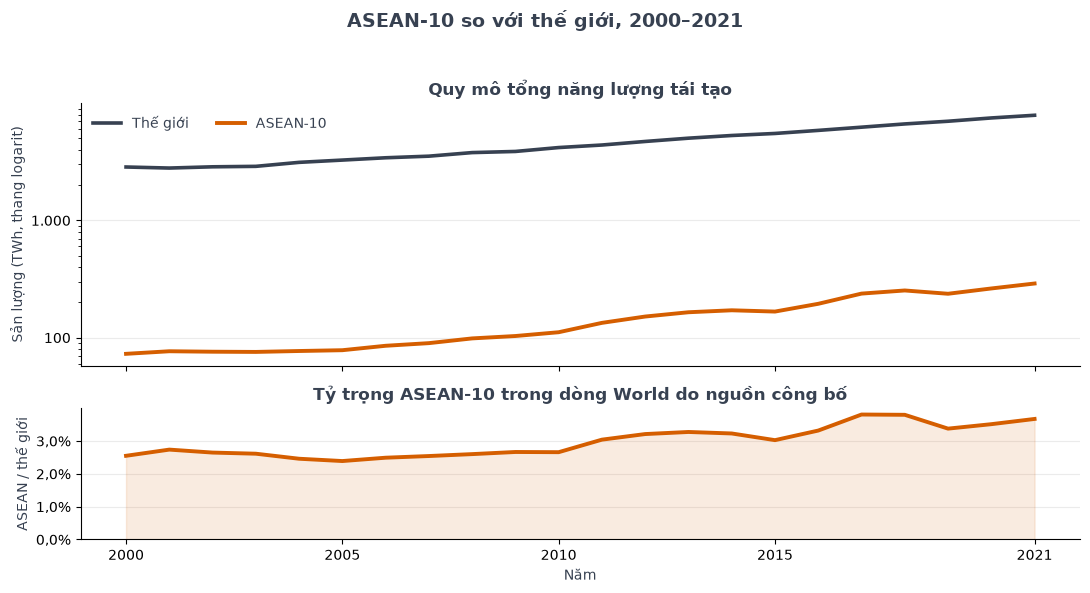

In [27]:
# Bước 5.2 — Tách sản lượng và tỷ trọng thành hai khung chung trục x để không cần trục kép.
years_plot = np.asarray(list(ANALYSIS_YEARS), dtype=int)
asean_total_plot = asean_totals["RENEWABLE_TOTAL"].to_numpy(dtype=float)
world_total_plot = world_totals["RENEWABLE_TOTAL"].to_numpy(dtype=float)
share_plot = asean_share_world["RENEWABLE_TOTAL"].to_numpy(dtype=float) * 100

fig, axes = plt.subplots(
    2, 1, figsize=(11, 6), dpi=100, sharex=True,
    gridspec_kw={"height_ratios": [2.0, 1.0]}
)
axes[0].plot(
    years_plot, world_total_plot, color=NEUTRAL_GRAY, linewidth=2.6, label="Thế giới"
)
axes[0].plot(
    years_plot, asean_total_plot, color=VIETNAM_HIGHLIGHT,
    linewidth=2.8, label="ASEAN-10"
)
axes[0].set_yscale("log")
axes[0].set_ylabel("Sản lượng (TWh, thang logarit)")
axes[0].set_title("Quy mô tổng năng lượng tái tạo")
axes[0].legend(frameon=False, ncol=2, loc="upper left")
axes[0].yaxis.set_major_formatter(
    matplotlib.ticker.FuncFormatter(lambda value, _: format_vi_number(value, 0))
)
style_axis(axes[0])

axes[1].plot(years_plot, share_plot, color=VIETNAM_HIGHLIGHT, linewidth=2.8)
axes[1].fill_between(years_plot, share_plot, color=VIETNAM_HIGHLIGHT, alpha=0.12)
axes[1].set_ylabel("ASEAN / thế giới")
axes[1].set_xlabel("Năm")
axes[1].set_title("Tỷ trọng ASEAN-10 trong dòng World do nguồn công bố")
axes[1].yaxis.set_major_formatter(
    matplotlib.ticker.FuncFormatter(lambda value, _: f"{format_vi_number(value, 1)}%")
)
axes[1].set_xticks([2000, 2005, 2010, 2015, 2021])
axes[1].set_ylim(bottom=0)
style_axis(axes[1])
fig.suptitle("ASEAN-10 so với thế giới, 2000–2021", fontsize=14, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

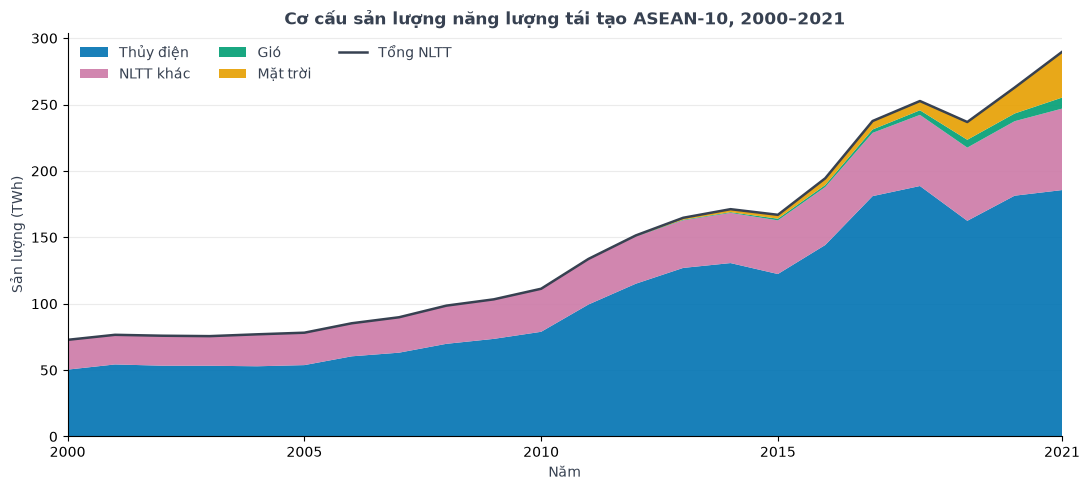

In [28]:
# Bước 5.3 — Chồng bốn thành phần có thể cộng để thấy đồng thời quy mô và dịch chuyển cơ cấu.
stack_order = ["HYDRO", "OTHER_RENEWABLES", "WIND", "SOLAR"]
stack_values = [asean_totals[key].to_numpy(dtype=float) for key in stack_order]
if any(np.isnan(values).any() for values in stack_values):
    raise ValueError("Không thể vẽ cơ cấu: tổng ASEAN có thành phần bị thiếu.")

fig, axis = plt.subplots(figsize=(11, 5), dpi=100)
axis.stackplot(
    years_plot,
    *stack_values,
    labels=[SERIES_LABELS_VI[key] for key in stack_order],
    colors=[TECHNOLOGY_COLORS[key] for key in stack_order],
    alpha=0.9,
)
axis.plot(
    years_plot, asean_total_plot, color=NEUTRAL_GRAY,
    linewidth=1.8, label="Tổng NLTT",
)
axis.set_title("Cơ cấu sản lượng năng lượng tái tạo ASEAN-10, 2000–2021")
axis.set_xlabel("Năm")
axis.set_ylabel("Sản lượng (TWh)")
axis.set_xticks([2000, 2005, 2010, 2015, 2021])
axis.set_xlim(2000, 2021)
axis.set_ylim(bottom=0)
axis.yaxis.set_major_formatter(
    matplotlib.ticker.FuncFormatter(lambda value, _: format_vi_number(value, 0))
)
axis.legend(frameon=False, ncol=3, loc="upper left")
style_axis(axis)
fig.tight_layout()
plt.show()

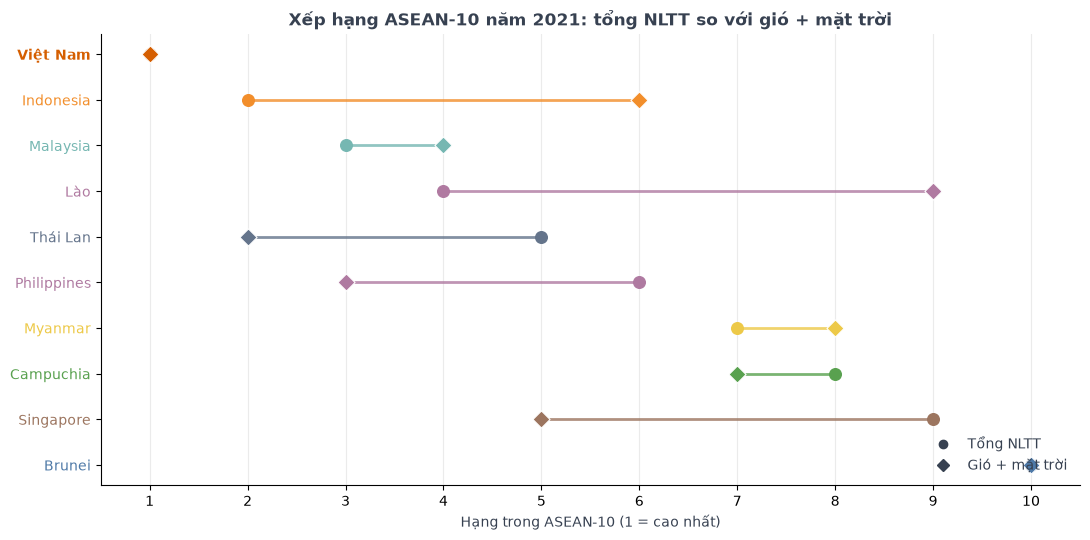

In [29]:
# Bước 5.4 — Nối hai hạng của cùng một nước để làm rõ mức đổi vị trí khi đổi thước đo.
ranking_2021 = (
    asean_rankings.loc[asean_rankings["year"].eq(2021)]
    .pivot(index="entity", columns="series", values="rank")
    .dropna(subset=["RENEWABLE_TOTAL", "MODERN_WIND_SOLAR"])
    .reset_index()
    .sort_values(["RENEWABLE_TOTAL", "entity"], kind="stable")
    .reset_index(drop=True)
)

fig, axis = plt.subplots(figsize=(11, 5.5), dpi=100)
y_positions = np.arange(len(ranking_2021))
for position, row in ranking_2021.iterrows():
    color = COUNTRY_COLORS[row["entity"]]
    is_vietnam = row["entity"] == "Vietnam"
    axis.plot(
        [row["RENEWABLE_TOTAL"], row["MODERN_WIND_SOLAR"]],
        [position, position],
        color=color,
        linewidth=3.2 if is_vietnam else 2.0,
        alpha=1.0 if is_vietnam else 0.8,
        zorder=2,
    )
    axis.scatter(
        row["RENEWABLE_TOTAL"], position, color=color, s=70, marker="o", zorder=3
    )
    axis.scatter(
        row["MODERN_WIND_SOLAR"], position, color=color, s=76,
        marker="D", edgecolor="white", linewidth=0.8, zorder=4
    )

axis.set_yticks(
    y_positions, [ENTITY_LABELS_VI[name] for name in ranking_2021["entity"]]
)
for tick, entity in zip(axis.get_yticklabels(), ranking_2021["entity"]):
    tick.set_color(COUNTRY_COLORS[entity])
    tick.set_fontweight("bold" if entity == "Vietnam" else "normal")
axis.invert_yaxis()
axis.set_xlim(0.5, 10.5)
axis.set_xticks(range(1, 11))
axis.set_xlabel("Hạng trong ASEAN-10 (1 = cao nhất)")
axis.set_title("Xếp hạng ASEAN-10 năm 2021: tổng NLTT so với gió + mặt trời")
axis.legend(
    handles=[
        matplotlib.lines.Line2D(
            [], [], marker="o", linestyle="", color=NEUTRAL_GRAY, label="Tổng NLTT"
        ),
        matplotlib.lines.Line2D(
            [], [], marker="D", linestyle="", color=NEUTRAL_GRAY, label="Gió + mặt trời"
        ),
    ],
    frameon=False,
    loc="lower right",
)
style_axis(axis, y_grid=False)
axis.grid(True, axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

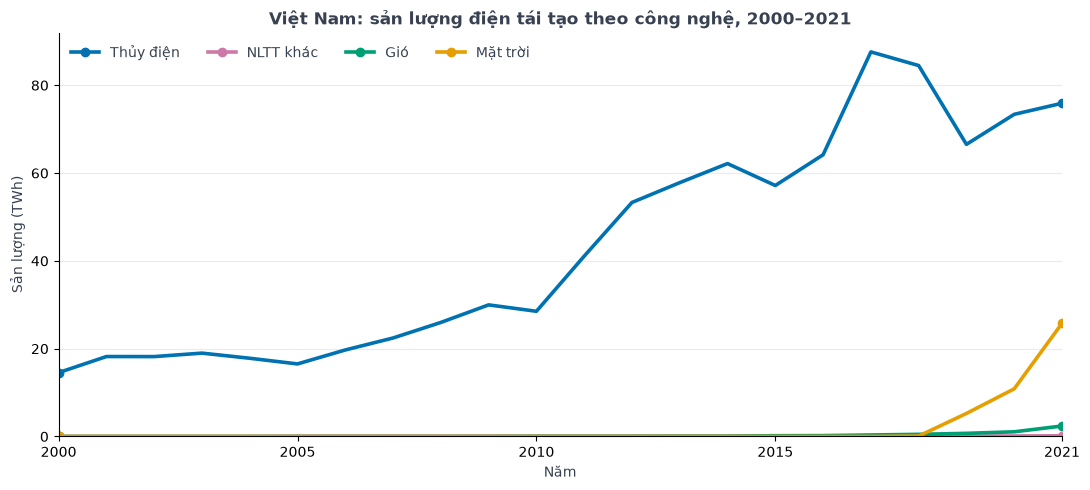

In [30]:
# Bước 5.5 — Giữ bốn đường trên cùng đơn vị TWh để so quỹ đạo mà không trộn thang đo.
vietnam_panel = asean_panel.loc[
    asean_panel["entity"].eq("Vietnam")
].sort_values("year")

fig, axis = plt.subplots(figsize=(11, 5), dpi=100)
for series in ["HYDRO", "OTHER_RENEWABLES", "WIND", "SOLAR"]:
    axis.plot(
        vietnam_panel["year"],
        vietnam_panel[series],
        color=TECHNOLOGY_COLORS[series],
        linewidth=2.6,
        marker="o",
        markevery=[0, -1],
        label=SERIES_LABELS_VI[series],
    )
axis.set_title("Việt Nam: sản lượng điện tái tạo theo công nghệ, 2000–2021")
axis.set_xlabel("Năm")
axis.set_ylabel("Sản lượng (TWh)")
axis.set_xticks([2000, 2005, 2010, 2015, 2021])
axis.set_xlim(2000, 2021)
axis.set_ylim(bottom=0)
axis.yaxis.set_major_formatter(
    matplotlib.ticker.FuncFormatter(lambda value, _: format_vi_number(value, 0))
)
axis.legend(frameon=False, ncol=4, loc="upper left")
style_axis(axis)
fig.tight_layout()
plt.show()

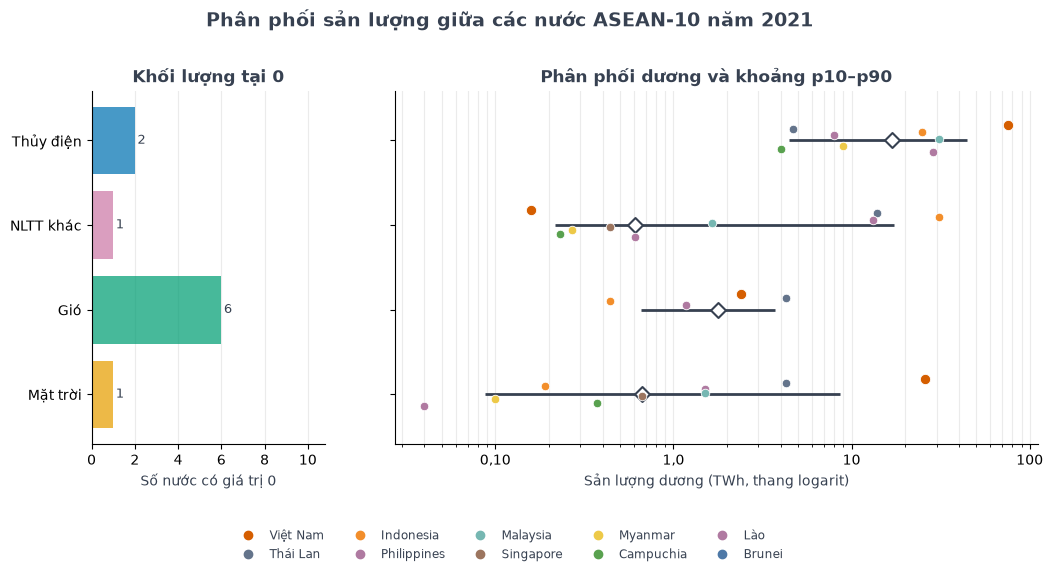

In [31]:
# Bước 5.6 — Đếm số 0 ở khung riêng; chỉ đưa giá trị > 0 vào trục logarit.
distribution_2021 = asean_panel.loc[asean_panel["year"].eq(2021)].melt(
    id_vars=["entity", "year"],
    value_vars=["HYDRO", "OTHER_RENEWABLES", "WIND", "SOLAR"],
    var_name="series",
    value_name="value",
)
zero_counts = (
    distribution_2021.assign(is_zero=distribution_2021["value"].eq(0))
    .groupby("series")["is_zero"]
    .sum()
    .reindex(["HYDRO", "OTHER_RENEWABLES", "WIND", "SOLAR"])
)
positive_distribution = distribution_2021.loc[
    distribution_2021["value"].gt(0)
].copy()
if not positive_distribution["value"].gt(0).all():
    raise AssertionError("Trục logarit nhận giá trị không dương.")

distribution_order = ["HYDRO", "OTHER_RENEWABLES", "WIND", "SOLAR"]
y_map = {series: index for index, series in enumerate(distribution_order)}
entity_offsets = dict(
    zip(ASEAN_COUNTRIES, np.linspace(-0.18, 0.18, len(ASEAN_COUNTRIES)))
)

fig, axes = plt.subplots(
    1, 2, figsize=(11, 5.8), dpi=100,
    gridspec_kw={"width_ratios": [0.8, 2.2]}, sharey=True
)
y_base = np.arange(len(distribution_order))
axes[0].barh(
    y_base,
    zero_counts.to_numpy(dtype=float),
    color=[TECHNOLOGY_COLORS[key] for key in distribution_order],
    alpha=0.72,
)
for position, count in enumerate(zero_counts):
    axes[0].text(float(count) + 0.12, position, str(int(count)), va="center", fontsize=9)
axes[0].set_xlim(0, 10.8)
axes[0].set_xticks(range(0, 11, 2))
axes[0].set_xlabel("Số nước có giá trị 0")
axes[0].set_title("Khối lượng tại 0")
axes[0].set_yticks(y_base, [SERIES_LABELS_VI[key] for key in distribution_order])
axes[0].invert_yaxis()
style_axis(axes[0], y_grid=False)
axes[0].grid(True, axis="x", alpha=0.25)

for series in distribution_order:
    subset = positive_distribution.loc[positive_distribution["series"].eq(series)]
    y_position = y_map[series]
    if not subset.empty:
        p10, median, p90 = np.percentile(
            subset["value"].to_numpy(dtype=float), [10, 50, 90], method="linear"
        )
        axes[1].hlines(
            y_position, p10, p90, color=NEUTRAL_GRAY, linewidth=2.0, zorder=1
        )
        axes[1].scatter(
            median, y_position, color="white", edgecolor=NEUTRAL_GRAY,
            marker="D", s=58, linewidth=1.5, zorder=3
        )
    for row in subset.itertuples(index=False):
        axes[1].scatter(
            row.value,
            y_position + entity_offsets[row.entity],
            color=COUNTRY_COLORS[row.entity],
            s=55 if row.entity == "Vietnam" else 38,
            edgecolor="white",
            linewidth=0.6,
            zorder=4,
        )

axes[1].set_xscale("log")
axes[1].set_xlabel("Sản lượng dương (TWh, thang logarit)")
axes[1].set_title("Phân phối dương và khoảng p10–p90")
axes[1].xaxis.set_major_formatter(
    matplotlib.ticker.FuncFormatter(
        lambda value, _: format_vi_number(
            value, 2 if value < 1 else 1 if value < 10 else 0
        )
    )
)
style_axis(axes[1], y_grid=False)
axes[1].grid(True, axis="x", which="both", alpha=0.25)

country_handles = [
    matplotlib.lines.Line2D(
        [], [], marker="o", linestyle="", color=COUNTRY_COLORS[entity],
        label=ENTITY_LABELS_VI[entity], markersize=6
    )
    for entity in ASEAN_COUNTRIES
]
fig.legend(
    handles=country_handles, frameon=False, loc="lower center",
    bbox_to_anchor=(0.5, 0.01), ncol=5, fontsize=8.5
)
fig.suptitle(
    "Phân phối sản lượng giữa các nước ASEAN-10 năm 2021",
    fontsize=14, fontweight="bold"
)
fig.subplots_adjust(left=0.12, right=0.98, top=0.84, bottom=0.23, wspace=0.16)
plt.show()